# Error profiles over time

For the seven frozen last-three-year predictors (reference years 2007–2013), what changed in errors through 2014, which features and concepts mark those errors, and were those groups present in the context? Evaluation patients supply reported results; later fitting-role entrants choose descriptions and ordering. Missed deaths are read first.


## 0. Can these frozen inputs reproduce the saved study?

Read cached predictions, embeddings and gradients without restoring or calling the predictor. Recompute timing from monthly events, replay every rule, compare all 864 encoded factors and reproduce every frozen concept's original direction ensemble (62 concepts). Data begin in 2007, so the 2007–2009 contexts hold every available year (one, two and three years); their saved builds carry other names (`r1`, `all_history`) but serve the same last-three-years setup, and the context years themselves are checked. The context-intervention baseline file has no 2007 rows, so the 2007 predictor is checked against its own saved build file only. The source stores factor codes as float16 and directions as float32; tolerances below are declared before comparison, and every mismatch outside them stops execution.


In [2]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from IPython.display import display
import error_profiles as ep

OUTPUT = Path("stats/error_profiles_over_time")
SEED, BOOTSTRAP_DRAWS, DIRECTION_FITS = 20261106, 1000, 50
TOLERANCES = {"activation": {"rtol": float(np.finfo(np.float16).eps), "atol": 1e-5},
              "float32": {"rtol": 1e-4, "atol": 1e-5}}
RIDGE_FOLDS, RIDGE_ALPHAS = 5, (.1, 1., 10., 100., 1000.)
TREE_FOLDS, WORKERS = 5, 8  # patient-grouped folds for every tree; CPU workers
OUTPUT.mkdir(parents=True, exist_ok=True)
started, timings = time.perf_counter(), {}
import json, hashlib, platform, os, sklearn
manifest = dict(status='running', started_utc=pd.Timestamp.now(tz='UTC').isoformat(), python=platform.python_version(),
                numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__, cpu_affinity=len(os.sched_getaffinity(0)),
                thread_env={k: os.environ.get(k) for k in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'CUDA_VISIBLE_DEVICES')},
                source_sha256={name: hashlib.sha256(Path(name).read_bytes()).hexdigest() if Path(name).exists() else None
                               for name in ('error_profiles.py', 'error_profiles_over_time.ipynb', 'tests/test_error_profiles.py')},
                helper_sha256=hashlib.sha256(Path(ep.__file__).read_bytes()).hexdigest())
(OUTPUT / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, default=str))


744

In [3]:
study = ep.load_study(TOLERANCES)
cases = study["cases"]
timings['0 load and parity'] = time.perf_counter() - started
for name in ("parity", "timing_coverage", "composition"):
    study[name].to_csv(OUTPUT / f"{name}.csv", index=False)
display(study["timing_coverage"])
display(study["parity"])
print(f"Frozen input checks: {study['load_seconds']:.1f} seconds")


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,reference,set,year,rows,timing_rows,no_timing,absent_timing_rows,death_only_zero_care_rows,zero_months
0,2007,evaluation,2007,237,237,0,0,3,3
1,2007,evaluation,2008,282,282,0,0,2,2
2,2007,evaluation,2009,296,296,0,0,1,1
3,2007,evaluation,2010,323,323,0,0,1,1
4,2007,evaluation,2011,319,319,0,0,4,4
...,...,...,...,...,...,...,...,...,...
65,2012,direction_fit,2012,159,159,0,0,1,1
66,2013,evaluation,2013,322,322,0,0,4,4
67,2013,evaluation,2014,324,324,0,0,0,0
68,2013,entrants,2014,246,246,0,0,0,0


,reference,check,seed,factors,rows,different_values,different_after_float16_rounding,rtol,atol,max_abs_error,...,one_death,one_survivor,one_patient,brier_skill,concept,matching_fit_patients,nonmatching_fit_patients,measured_fits,negative_pool,negative_cutoff
0,2007,864-factor encoding,42.0,288.0,2426.0,330589.0,366.0,0.000977,0.00001,3.903389e-03,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2007,864-factor encoding,135.0,288.0,2426.0,332535.0,394.0,0.000977,0.00001,3.549576e-03,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2007,864-factor encoding,215.0,288.0,2426.0,332264.0,364.0,0.000977,0.00001,3.891945e-03,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2007,baseline (no saved copy),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.055556,0.004566,0.004219,0.083072,NaN,NaN,NaN,NaN,NaN,NaN
4,2007,baseline (no saved copy),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.033333,0.003968,0.003546,0.027977,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113,2013,rule/direction,NaN,NaN,NaN,NaN,NaN,0.000100,0.00001,1.484521e-08,...,NaN,NaN,NaN,NaN,"last_3/2013/2013/42/42:279,135:39,215:216",25.0,83.0,50.0,minimum activation among reference fitting pat...,0.0
114,2013,rule/direction,NaN,NaN,NaN,NaN,NaN,0.000100,0.00001,1.462413e-08,...,NaN,NaN,NaN,NaN,"last_3/2013/2013/42/42:3,135:69,215:27",24.0,59.0,50.0,minimum activation among reference fitting pat...,0.0
115,2013,rule/direction,NaN,NaN,NaN,NaN,NaN,0.000100,0.00001,1.481280e-08,...,NaN,NaN,NaN,NaN,"last_3/2013/2013/42/42:69,135:167,215:21",9.0,83.0,50.0,minimum activation among reference fitting pat...,0.0
116,2013,rule/direction,NaN,NaN,NaN,NaN,NaN,0.000100,0.00001,1.481068e-08,...,NaN,NaN,NaN,NaN,"last_3/2013/2013/42/42:80,135:92,215:162",8.0,86.0,50.0,minimum activation among reference fitting pat...,0.0


Frozen input checks: 15.8 seconds


Read timing coverage before interpreting a record-length adjustment. A missing timing row is never zero months; incomplete reference-year coverage disables timing-dependent results. Original concept directions used only minimum-activation rule negatives: their verification reproduces that pool exactly. New rule directions use every rule-negative fitting patient, as specified for this diagnostic, retaining the original seeds, resampling, class mass, solver and normalization.


Choosing entrants must first appear in the population after the reference year and hold the original fitting role; they share no patient with evaluation or the actual context. The upstream entrant flag also includes patients returning after a gap, so that flag alone is insufficient. The composition table prints those excluded gap returners and their context exposure. Newcomers in any reported year mean first_year == year; returning means first_year < year.


An existing DEATH-only monthly-event row has an observed empty care-event set: its months with care are zero. The source timing function outer-joins this death onto the empty care grouping, leaving care counts as NaN; the adapter records this proven zero separately. A genuinely absent timing row remains unknown. Zero-month deaths are a separate record-length stratum.


## 1. What happened to the errors?

The frozen threshold determines four disjoint groups. Resample a patient together in every year and predictor, using 1,000 shared draws; report annual values and reference versus later years pooled, with actual counts and one-patient increments. The annual score fits and shifts are refitted in the same draws for later comparisons.


In [4]:
patient_sets = [view['frame']['patient_id'].to_numpy() for case in cases
                for name, view in case['views'].items() if name in ('evaluation', 'entrants')]
bootstrap = ep.patient_bootstrap(patient_sets, BOOTSTRAP_DRAWS, SEED)
analysis = {}
for case in cases:
    ref, frame = case['reference'], case['views']['evaluation']['frame']
    weights = ep.row_weights(frame['patient_id'], bootstrap)
    risks, shifted, nuisance = ep.annual_benchmarks(frame, weights, ref)
    performance = ep.performance_table(frame, weights, case['threshold'], ref, shifted)
    analysis[ref] = dict(weights=weights, risks=risks, shifted=shifted, nuisance=nuisance,
                         performance=performance)
    nuisance.to_csv(OUTPUT / f'{ref}_score_fits_and_shifts.csv', index=False)
    performance.to_csv(OUTPUT / f'{ref}_performance.csv', index=False)
    display(performance[performance['version'] == 'frozen'])

,reference,period,version,metric,rows,patients,deaths,survivors,numerator,denominator,zero_observed_events,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status,patient_equivalent
0,2007,2007,frozen,n,237,237,18,219,237.0,1.0,False,237.000000,207.000000,265.025000,1000,0,False,estimated,NaN
1,2007,2007,frozen,deaths,237,237,18,219,18.0,1.0,False,18.000000,11.000000,27.000000,1000,0,False,estimated,NaN
2,2007,2007,frozen,survivors,237,237,18,219,219.0,1.0,False,219.000000,190.000000,247.000000,1000,0,False,estimated,NaN
3,2007,2007,frozen,true_positives,237,237,18,219,9.0,1.0,False,9.000000,4.000000,15.000000,1000,0,False,estimated,NaN
4,2007,2007,frozen,false_positives,237,237,18,219,20.0,1.0,False,20.000000,12.000000,30.000000,1000,0,False,estimated,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
489,2007,2007→2011,frozen,one_patient,319,319,23,296,NaN,NaN,NaN,-0.001085,-0.001618,-0.000581,1000,0,False,estimated,NaN
490,2007,2007→2012,frozen,one_patient,311,311,23,288,NaN,NaN,NaN,-0.001004,-0.001581,-0.000489,1000,0,False,estimated,NaN
491,2007,2007→2013,frozen,one_patient,332,332,26,306,NaN,NaN,NaN,-0.001207,-0.001795,-0.000721,1000,0,False,estimated,NaN
492,2007,2007→2014,frozen,one_patient,326,326,28,298,NaN,NaN,NaN,-0.001152,-0.001743,-0.000628,1000,0,False,estimated,NaN


,reference,period,version,metric,rows,patients,deaths,survivors,numerator,denominator,zero_observed_events,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status,patient_equivalent
0,2008,2008,frozen,n,298,298,22,276,298.0,1.0,False,298.000000,265.000000,328.000000,1000,0,False,estimated,NaN
1,2008,2008,frozen,deaths,298,298,22,276,22.0,1.0,False,22.000000,13.000000,31.000000,1000,0,False,estimated,NaN
2,2008,2008,frozen,survivors,298,298,22,276,276.0,1.0,False,276.000000,244.000000,305.000000,1000,0,False,estimated,NaN
3,2008,2008,frozen,true_positives,298,298,22,276,10.0,1.0,False,10.000000,4.000000,17.000000,1000,0,False,estimated,NaN
4,2008,2008,frozen,false_positives,298,298,22,276,34.0,1.0,False,34.000000,23.000000,45.000000,1000,0,False,estimated,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
432,2008,2008→2011,frozen,one_patient,325,325,41,284,NaN,NaN,NaN,-0.000279,-0.000652,0.000086,1000,0,False,estimated,NaN
433,2008,2008→2012,frozen,one_patient,310,310,28,282,NaN,NaN,NaN,-0.000130,-0.000528,0.000283,1000,0,False,estimated,NaN
434,2008,2008→2013,frozen,one_patient,314,314,27,287,NaN,NaN,NaN,-0.000171,-0.000581,0.000248,1000,0,False,estimated,NaN
435,2008,2008→2014,frozen,one_patient,309,309,19,290,NaN,NaN,NaN,-0.000119,-0.000537,0.000305,1000,0,False,estimated,NaN


,reference,period,version,metric,rows,patients,deaths,survivors,numerator,denominator,zero_observed_events,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status,patient_equivalent
0,2009,2009,frozen,n,310,310,27,283,310.0,1.0,False,310.000000,276.000000,344.000000,1000,0,False,estimated,NaN
1,2009,2009,frozen,deaths,310,310,27,283,27.0,1.0,False,27.000000,17.000000,37.000000,1000,0,False,estimated,NaN
2,2009,2009,frozen,survivors,310,310,27,283,283.0,1.0,False,283.000000,250.000000,316.000000,1000,0,False,estimated,NaN
3,2009,2009,frozen,true_positives,310,310,27,283,8.0,1.0,False,8.000000,3.000000,14.000000,1000,0,False,estimated,NaN
4,2009,2009,frozen,false_positives,310,310,27,283,20.0,1.0,False,20.000000,12.000000,29.000000,1000,0,False,estimated,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375,2009,2009→2011,frozen,one_patient,305,305,32,273,NaN,NaN,NaN,0.000053,-0.000292,0.000382,1000,0,False,estimated,NaN
376,2009,2009→2012,frozen,one_patient,329,329,32,297,NaN,NaN,NaN,-0.000186,-0.000544,0.000130,1000,0,False,estimated,NaN
377,2009,2009→2013,frozen,one_patient,329,329,31,298,NaN,NaN,NaN,-0.000186,-0.000578,0.000143,1000,0,False,estimated,NaN
378,2009,2009→2014,frozen,one_patient,325,325,28,297,NaN,NaN,NaN,-0.000149,-0.000549,0.000211,1000,0,False,estimated,NaN


,reference,period,version,metric,rows,patients,deaths,survivors,numerator,denominator,zero_observed_events,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status,patient_equivalent
0,2010,2010,frozen,n,324,324,27,297,324.0,1.0,False,324.000000,289.000000,360.000000,1000,0,False,estimated,NaN
1,2010,2010,frozen,deaths,324,324,27,297,27.0,1.0,False,27.000000,18.000000,39.000000,1000,0,False,estimated,NaN
2,2010,2010,frozen,survivors,324,324,27,297,297.0,1.0,False,297.000000,264.000000,329.025000,1000,0,False,estimated,NaN
3,2010,2010,frozen,true_positives,324,324,27,297,13.0,1.0,False,13.000000,6.000000,21.000000,1000,0,False,estimated,NaN
4,2010,2010,frozen,false_positives,324,324,27,297,13.0,1.0,False,13.000000,6.000000,21.000000,1000,0,False,estimated,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318,2010,2010→2011,frozen,one_patient,303,303,28,275,NaN,NaN,NaN,0.000214,-0.000065,0.000512,1000,0,False,estimated,NaN
319,2010,2010→2012,frozen,one_patient,319,319,22,297,NaN,NaN,NaN,0.000048,-0.000276,0.000366,1000,0,False,estimated,NaN
320,2010,2010→2013,frozen,one_patient,320,320,20,300,NaN,NaN,NaN,0.000039,-0.000297,0.000371,1000,0,False,estimated,NaN
321,2010,2010→2014,frozen,one_patient,318,318,33,285,NaN,NaN,NaN,0.000058,-0.000298,0.000438,1000,0,False,estimated,NaN


,reference,period,version,metric,rows,patients,deaths,survivors,numerator,denominator,zero_observed_events,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status,patient_equivalent
0,2011,2011,frozen,n,314,314,32,282,314.0,1.0,False,314.000000,283.000000,347.000000,1000,0,False,estimated,NaN
1,2011,2011,frozen,deaths,314,314,32,282,32.0,1.0,False,32.000000,22.000000,44.000000,1000,0,False,estimated,NaN
2,2011,2011,frozen,survivors,314,314,32,282,282.0,1.0,False,282.000000,250.000000,313.000000,1000,0,False,estimated,NaN
3,2011,2011,frozen,true_positives,314,314,32,282,31.0,1.0,False,31.000000,21.000000,42.000000,1000,0,False,estimated,NaN
4,2011,2011,frozen,false_positives,314,314,32,282,86.0,1.0,False,86.000000,68.000000,105.000000,1000,0,False,estimated,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,2011,2011→later,frozen,one_survivor,993,458,82,911,NaN,NaN,NaN,-0.002448,-0.002796,-0.002161,1000,0,False,estimated,NaN
262,2011,2011→2012,frozen,one_patient,326,326,36,290,NaN,NaN,NaN,-0.000117,-0.000340,0.000110,1000,0,False,estimated,NaN
263,2011,2011→2013,frozen,one_patient,334,334,22,312,NaN,NaN,NaN,-0.000191,-0.000463,0.000074,1000,0,False,estimated,NaN
264,2011,2011→2014,frozen,one_patient,333,333,24,309,NaN,NaN,NaN,-0.000182,-0.000475,0.000107,1000,0,False,estimated,NaN


,reference,period,version,metric,rows,patients,deaths,survivors,numerator,denominator,zero_observed_events,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status,patient_equivalent
0,2012,2012,frozen,n,316,316,27,289,316.0,1.0,False,316.000000,283.000000,347.025000,1000,0,False,estimated,NaN
1,2012,2012,frozen,deaths,316,316,27,289,27.0,1.0,False,27.000000,17.975000,39.000000,1000,0,False,estimated,NaN
2,2012,2012,frozen,survivors,316,316,27,289,289.0,1.0,False,289.000000,257.000000,318.000000,1000,0,False,estimated,NaN
3,2012,2012,frozen,true_positives,316,316,27,289,24.0,1.0,False,24.000000,15.000000,34.000000,1000,0,False,estimated,NaN
4,2012,2012,frozen,false_positives,316,316,27,289,56.0,1.0,False,56.000000,42.000000,70.000000,1000,0,False,estimated,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,2012,2012→2014,frozen,one_survivor,302,302,26,276,NaN,NaN,NaN,0.000163,-0.000130,0.000490,1000,0,False,estimated,NaN
205,2012,2012→later,frozen,one_survivor,627,374,53,574,NaN,NaN,NaN,-0.001718,-0.002023,-0.001484,1000,0,False,estimated,NaN
206,2012,2012→2013,frozen,one_patient,325,325,27,298,NaN,NaN,NaN,-0.000088,-0.000299,0.000146,1000,0,False,estimated,NaN
207,2012,2012→2014,frozen,one_patient,302,302,26,276,NaN,NaN,NaN,0.000147,-0.000104,0.000433,1000,0,False,estimated,NaN


,reference,period,version,metric,rows,patients,deaths,survivors,numerator,denominator,zero_observed_events,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status,patient_equivalent
0,2013,2013,frozen,n,322,322,24,298,322.0,1.0,False,322.000000,287.000000,357.000000,1000,0,False,estimated,NaN
1,2013,2013,frozen,deaths,322,322,24,298,24.0,1.0,False,24.000000,15.000000,35.000000,1000,0,False,estimated,NaN
2,2013,2013,frozen,survivors,322,322,24,298,298.0,1.0,False,298.000000,265.000000,332.000000,1000,0,False,estimated,NaN
3,2013,2013,frozen,true_positives,322,322,24,298,12.0,1.0,False,12.000000,5.000000,19.000000,1000,0,False,estimated,NaN
4,2013,2013,frozen,false_positives,322,322,24,298,35.0,1.0,False,35.000000,24.000000,47.000000,1000,0,False,estimated,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147,2013,2013→later,frozen,one_death,324,324,26,298,NaN,NaN,NaN,-0.003205,-0.027579,0.022515,1000,0,False,estimated,NaN
148,2013,2013→2014,frozen,one_survivor,324,324,26,298,NaN,NaN,NaN,0.000000,-0.000271,0.000247,1000,0,False,estimated,NaN
149,2013,2013→later,frozen,one_survivor,324,324,26,298,NaN,NaN,NaN,0.000000,-0.000271,0.000247,1000,0,False,estimated,NaN
150,2013,2013→2014,frozen,one_patient,324,324,26,298,NaN,NaN,NaN,-0.000019,-0.000233,0.000197,1000,0,False,estimated,NaN


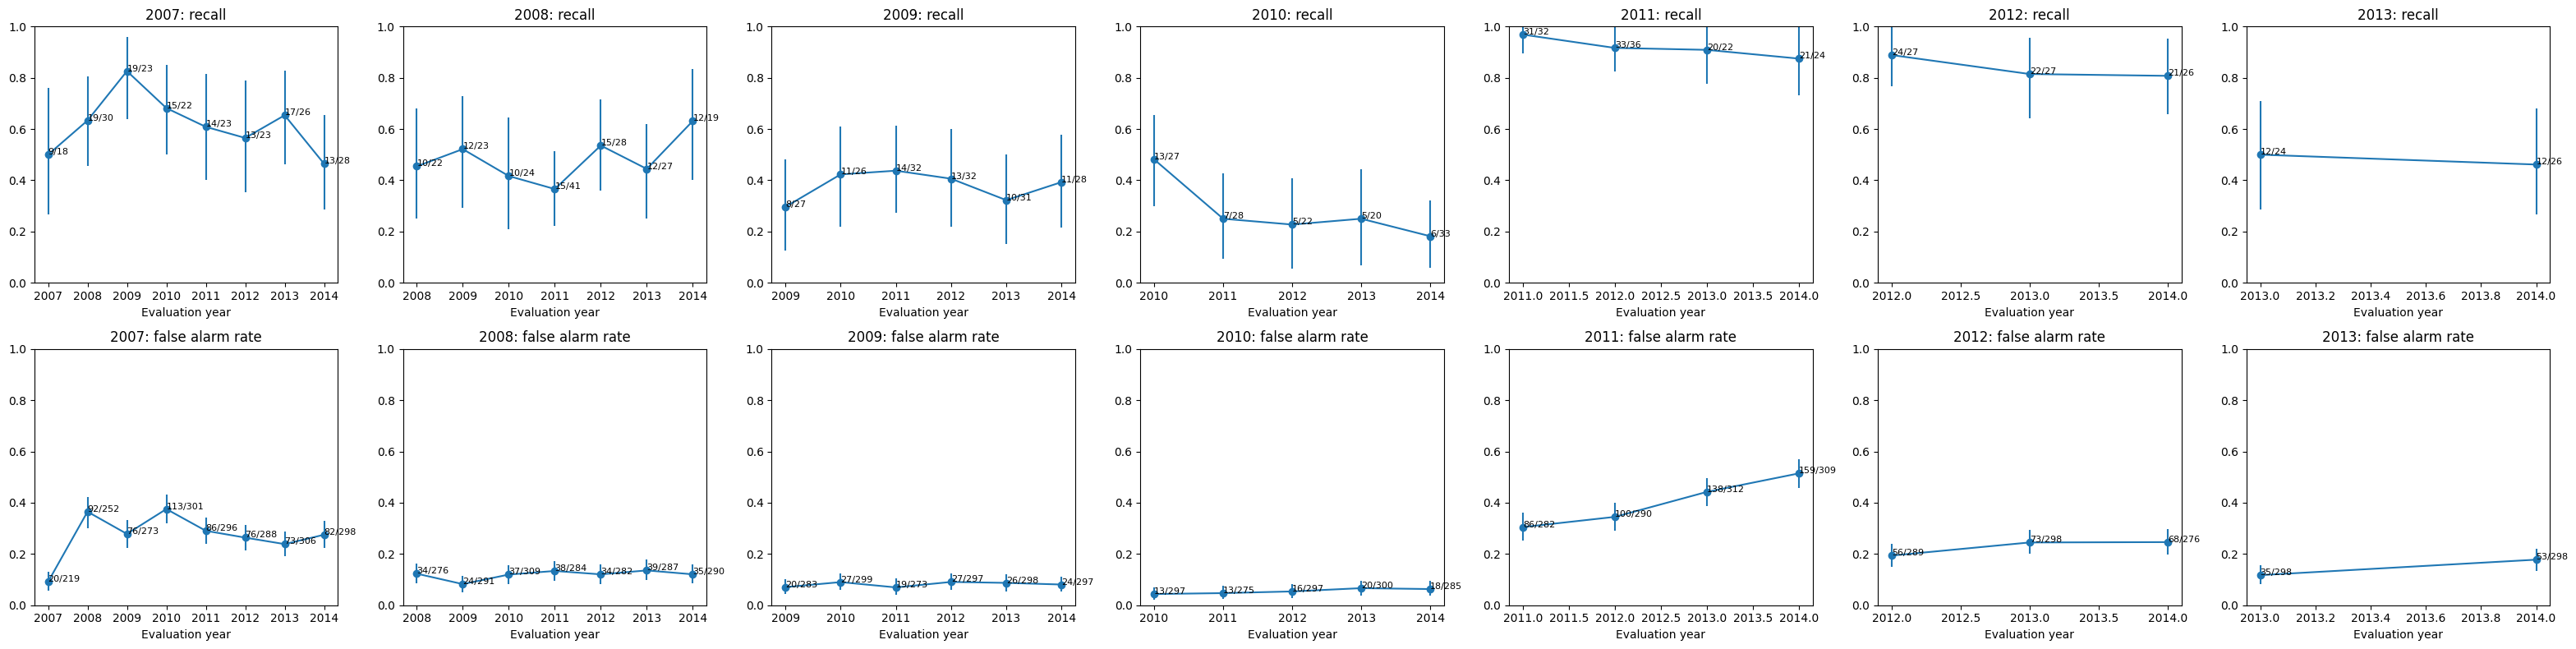

In [5]:
fig, axes = plt.subplots(2, len(cases), figsize=(4.5 * len(cases), 8), squeeze=False)
for col, case in enumerate(cases):
    ref, table = case['reference'], analysis[case['reference']]['performance']
    for row, metric in enumerate(('recall', 'false_alarm_rate')):
        part = table[(table['version'] == 'frozen') & (table['metric'] == metric) & table['period'].str.fullmatch(r'\d{4}')]
        x = part['period'].astype(int).to_numpy(); ax = axes[row, col]
        ax.plot(x, part['value'], marker='o'); ax.vlines(x, part['low'], part['high'])
        for year, point in zip(x, part.to_dict('records')):
            ax.annotate(f"{int(point['numerator'])}/{int(point['denominator'])}", (year, point['value']), fontsize=8)
        ax.set(title=f'{ref}: {metric.replace("_", " ")}', xlabel='Evaluation year', ylim=(0, 1))
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_01_error_rates.png', dpi=160)
plt.show()

Read missed deaths first: recall is caught deaths divided by all deaths. False-alarm rate is flagged survivors divided by all survivors. Counts explain how much one patient changes a rate; percentile intervals that collapse at zero events cannot create unseen events. AUROC, average precision, Death-F1, Brier, mortality, mean score and share flagged are all in the complete performance files. Undefined draws remain counted.


## 2. Would a uniform score shift restore the operating point?

For each year, shift the log-odds by one constant until mean score minus mortality matches the reference-year gap. The frozen threshold stays fixed; shifted and original recall and false-alarm rate have paired patient intervals. Exact probability endpoints are counted and clipped only for numerical logit fitting, using the declared source-dtype epsilon; sensitivity at an endpoint remains undefined.


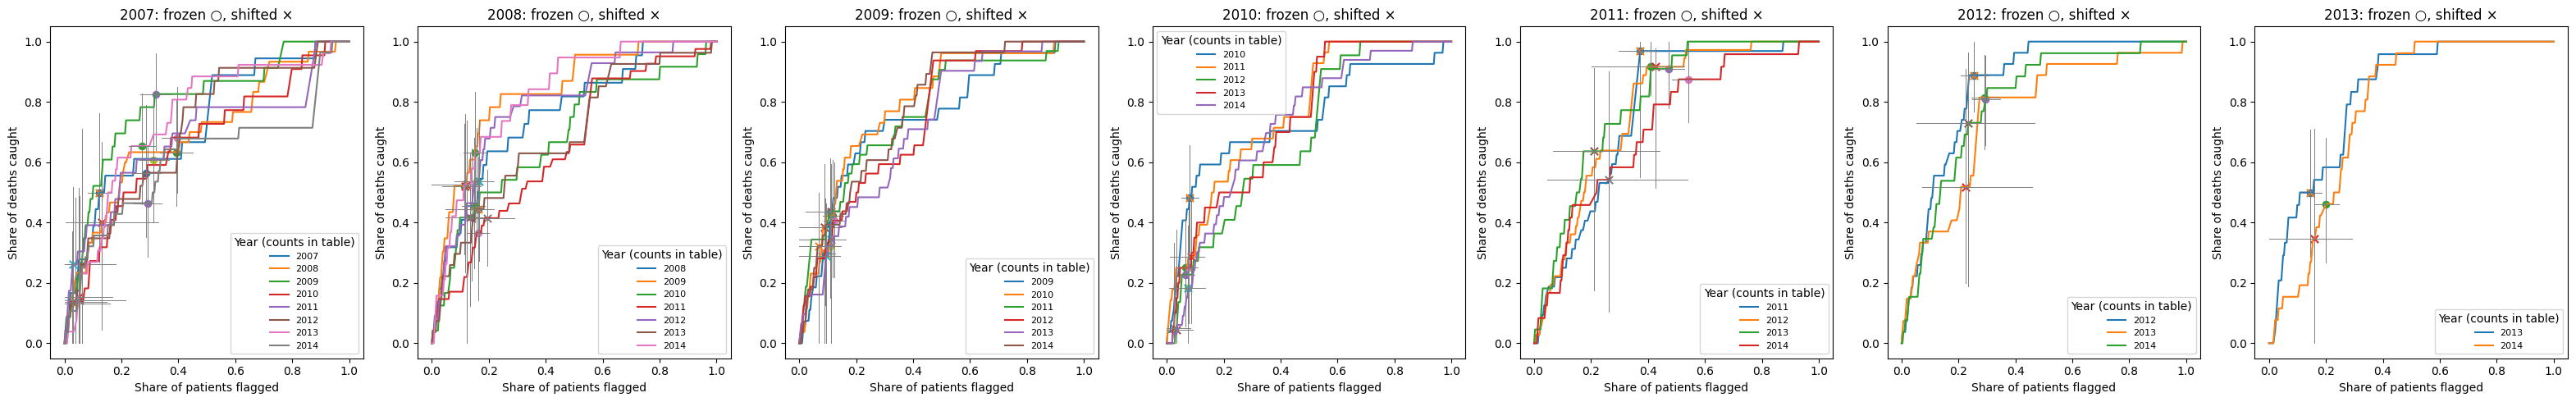

In [6]:
fig, axes = plt.subplots(1, len(cases), figsize=(4.5 * len(cases), 5), squeeze=False)
for col, case in enumerate(cases):
    ref, frame, ax = case['reference'], case['views']['evaluation']['frame'], axes[0, col]
    for year, part in frame.groupby('year'):
        p, y = part['probability'].to_numpy(), part['label'].to_numpy()
        order = np.argsort(-p, kind='stable'); ends = np.r_[np.flatnonzero(np.diff(p[order]) != 0), len(p)-1]
        ax.plot(np.r_[0, (ends+1)/len(p)], np.r_[0, np.cumsum(y[order])[ends]/y.sum()], label=str(year))
        frozen = p >= case['threshold']; shifted_p = analysis[ref]['shifted'][0, part.index]
        period = str(year); perf = analysis[ref]['performance'].query('period == @period and metric in ["recall", "share_flagged"]').set_index(['version', 'metric'])
        for version in ('frozen', 'shifted'):
            r, s = perf.loc[(version, 'recall')], perf.loc[(version, 'share_flagged')]
            ax.plot([s['low'], s['high']], [r['value']] * 2, color='grey', lw=.7)  # percentile intervals need not
            ax.plot([s['value']] * 2, [r['low'], r['high']], color='grey', lw=.7)  # contain the point estimate
        ax.scatter(frozen.mean(), y[frozen].sum()/y.sum(), marker='o', s=35)
        if np.isfinite(shifted_p).all():
            shifted = shifted_p >= case['threshold']; ax.scatter(shifted.mean(), y[shifted].sum()/y.sum(), marker='x', s=45)
        else:
            print(f'{ref}/{year}: shifted operating point not estimable; n={len(part)}')
    ax.set(title=f'{ref}: frozen ○, shifted ×', xlabel='Share of patients flagged', ylabel='Share of deaths caught')
    ax.legend(title='Year (counts in table)', fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_02_operating_point.png', dpi=160); plt.show()

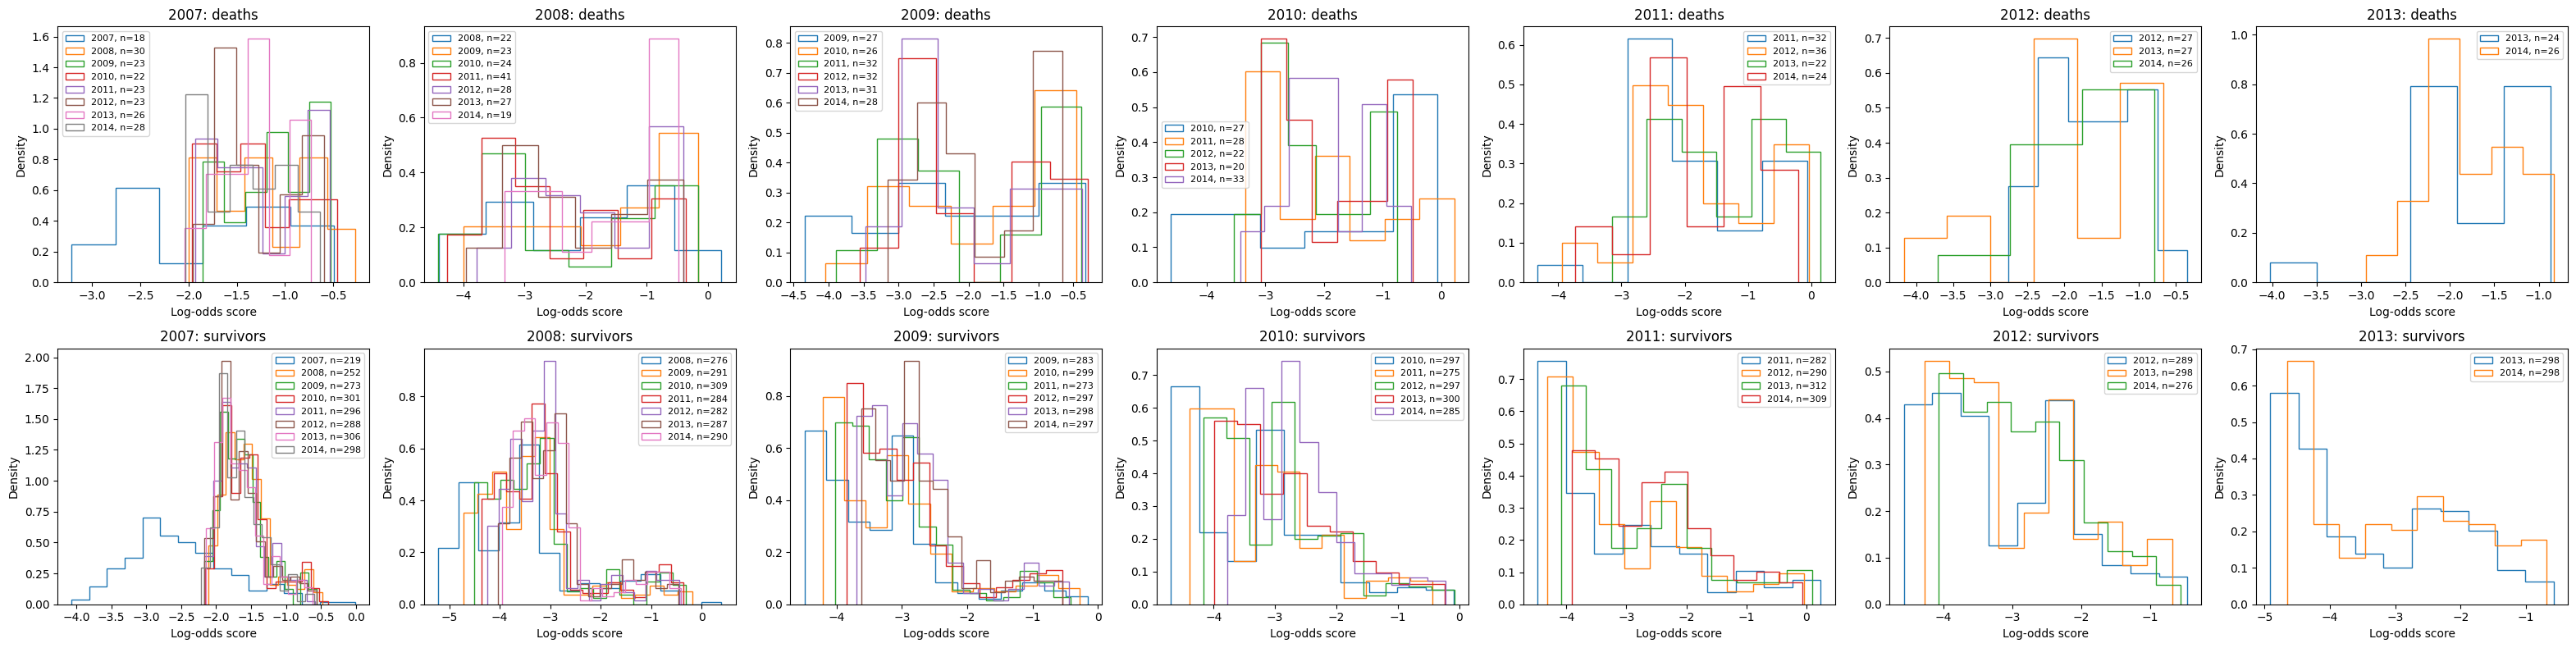

In [7]:
fig, axes = plt.subplots(2, len(cases), figsize=(4.5 * len(cases), 8), squeeze=False)
for col, case in enumerate(cases):
    frame = case['views']['evaluation']['frame']
    for row, label in enumerate((1, 0)):
        ax = axes[row, col]
        for year, part in frame[frame['label'] == label].groupby('year'):
            values, eps = ep.score_logits(part['probability'].to_numpy())
            ax.hist(values, bins='auto', density=True, histtype='step', label=f'{year}, n={len(part)}')
        ax.set(title=f"{case['reference']}: {'deaths' if label else 'survivors'}", xlabel='Log-odds score', ylabel='Density')
        ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_03_score_distributions.png', dpi=160); plt.show()

A displaced point on a similar ranking curve suggests an operating-point movement; a changed curve suggests deaths also moved within the ranking. The score-alone benchmark fits intercept and slope of outcome against log-odds score separately each year. Plain, unadjusted results are the main result throughout: annual score fits absorb overall annual change, record length is itself part of how errors arise, and neither adjustment makes the remaining change unreal. This two-number score fit is a benchmark, not proof that every score explanation was removed.


In [8]:
for case in cases:
    ref, results = case['reference'], analysis[case['reference']]
    display(results['nuisance'][results['nuisance']['draw'] == 0])
    failures = results['nuisance'].groupby(['year', 'status', 'shift_status']).size().rename('draws').reset_index()
    failures.to_csv(OUTPUT / f'{ref}_nuisance_fit_coverage.csv', index=False)
    display(failures)
    display(results['performance'].query("metric in ['recall', 'false_alarm_rate']"))

,reference,draw,year,status,intercept,slope,endpoint_count,logit_clip_epsilon,rows,weighted_rows,weighted_deaths,shift_status,shift_offset,shift_target_mean_score,shift_endpoint_count,shift_logit_clip_epsilon,shift_weighted_rows
0,2007,0,2007,fitted,0.188202,1.246847,0,1.192093e-07,237,237.0,18.0,fitted,-4.588596e-13,0.097113,0,1.192093e-07,237
1,2007,0,2008,fitted,0.845492,2.128669,0,1.192093e-07,282,282.0,30.0,fitted,-4.549730e-01,0.127547,0,1.192093e-07,282
2,2007,0,2009,fitted,1.824320,3.066422,0,1.192093e-07,296,296.0,23.0,fitted,-6.802753e-01,0.098867,0,1.192093e-07,296
3,2007,0,2010,fitted,-0.326985,1.583757,0,1.192093e-07,323,323.0,22.0,fitted,-8.320089e-01,0.089275,0,1.192093e-07,323
4,2007,0,2011,fitted,0.810246,2.305773,0,1.192093e-07,319,319.0,23.0,fitted,-7.323329e-01,0.093264,0,1.192093e-07,319
5,2007,0,2012,fitted,0.495239,2.030125,0,1.192093e-07,311,311.0,23.0,fitted,-6.948738e-01,0.095119,0,1.192093e-07,311
6,2007,0,2013,fitted,1.228976,2.451060,0,1.192093e-07,332,332.0,26.0,fitted,-6.144676e-01,0.099477,0,1.192093e-07,332
7,2007,0,2014,fitted,0.304130,1.717362,0,1.192093e-07,326,326.0,28.0,fitted,-5.296922e-01,0.107054,0,1.192093e-07,326


,year,status,shift_status,draws
0,2007,fitted,fitted,1001
1,2008,fitted,fitted,1001
2,2009,fitted,fitted,1001
3,2010,fitted,fitted,1001
4,2011,fitted,fitted,1001
5,2012,fitted,fitted,1001
6,2013,fitted,fitted,1001
7,2014,fitted,fitted,1001


,reference,period,version,metric,rows,patients,deaths,survivors,numerator,denominator,zero_observed_events,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status,patient_equivalent
6,2007,2007,frozen,recall,237,237,18,219,9.0,18.0,False,0.500000,0.266579,0.761905,1000,0,False,estimated,NaN
7,2007,2007,frozen,false_alarm_rate,237,237,18,219,20.0,219.0,False,0.091324,0.055837,0.131224,1000,0,False,estimated,NaN
25,2007,2007,shifted,recall,237,237,18,219,9.0,18.0,False,0.500000,0.266579,0.761905,1000,0,False,estimated,NaN
26,2007,2007,shifted,false_alarm_rate,237,237,18,219,20.0,219.0,False,0.091324,0.055837,0.131224,1000,0,False,estimated,NaN
44,2007,2008,frozen,recall,282,282,30,252,19.0,30.0,False,0.633333,0.454545,0.806452,1000,0,False,estimated,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
553,2007,2007→2011,shifted,false_alarm_rate,319,319,23,296,NaN,NaN,NaN,-0.077811,-0.115556,0.046634,1000,0,False,estimated,-23.031963
554,2007,2007→2012,shifted,false_alarm_rate,311,311,23,288,NaN,NaN,NaN,-0.060074,-0.114044,0.045840,1000,0,False,estimated,-17.301370
555,2007,2007→2013,shifted,false_alarm_rate,332,332,26,306,NaN,NaN,NaN,-0.048841,-0.111687,0.045437,1000,0,False,estimated,-14.945205
556,2007,2007→2014,shifted,false_alarm_rate,326,326,28,298,NaN,NaN,NaN,-0.047700,-0.110370,0.090667,1000,0,False,estimated,-14.214612


,reference,draw,year,status,intercept,slope,endpoint_count,logit_clip_epsilon,rows,weighted_rows,weighted_deaths,shift_status,shift_offset,shift_target_mean_score,shift_endpoint_count,shift_logit_clip_epsilon,shift_weighted_rows
0,2008,0,2008,fitted,-0.275392,0.790431,0,1.192093e-07,298,298.0,22.0,fitted,-1.085422e-17,0.064104,0,1.192093e-07,298
1,2008,0,2009,fitted,0.537783,1.162091,0,1.192093e-07,314,314.0,23.0,fitted,1.449013e-02,0.063527,0,1.192093e-07,314
2,2008,0,2010,fitted,-0.556483,0.709707,0,1.192093e-07,333,333.0,24.0,fitted,-8.043779e-02,0.062351,0,1.192093e-07,333
3,2008,0,2011,fitted,-0.380476,0.554947,0,1.192093e-07,325,325.0,41.0,fitted,5.849380e-01,0.116432,0,1.192093e-07,325
4,2008,0,2012,fitted,0.473818,1.109254,0,1.192093e-07,310,310.0,28.0,fitted,1.003155e-01,0.080601,0,1.192093e-07,310
5,2008,0,2013,fitted,-0.255337,0.824529,0,1.192093e-07,314,314.0,27.0,fitted,-1.443472e-02,0.076266,0,1.192093e-07,314
6,2008,0,2014,fitted,0.150786,1.232767,0,1.192093e-07,309,309.0,19.0,fitted,-4.905653e-01,0.051767,0,1.192093e-07,309


,year,status,shift_status,draws
0,2008,fitted,fitted,1001
1,2009,fitted,fitted,1000
2,2009,fitted,impossible calibration target,1
3,2010,fitted,fitted,1000
4,2010,fitted,impossible calibration target,1
5,2011,fitted,fitted,1001
6,2012,fitted,fitted,1001
7,2013,fitted,fitted,1001
8,2014,fitted,fitted,998
9,2014,fitted,impossible calibration target,3


,reference,period,version,metric,rows,patients,deaths,survivors,numerator,denominator,zero_observed_events,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status,patient_equivalent
6,2008,2008,frozen,recall,298,298,22,276,10.0,22.0,False,0.454545,0.249702,0.680000,1000,0,False,estimated,NaN
7,2008,2008,frozen,false_alarm_rate,298,298,22,276,34.0,276.0,False,0.123188,0.086189,0.161072,1000,0,False,estimated,NaN
25,2008,2008,shifted,recall,298,298,22,276,10.0,22.0,False,0.454545,0.249702,0.680000,1000,0,False,estimated,NaN
26,2008,2008,shifted,false_alarm_rate,298,298,22,276,34.0,276.0,False,0.123188,0.086189,0.161072,1000,0,False,estimated,NaN
44,2008,2009,frozen,recall,314,314,23,291,12.0,23.0,False,0.521739,0.294056,0.727273,1000,0,False,estimated,NaN
45,2008,2009,frozen,false_alarm_rate,314,314,23,291,24.0,291.0,False,0.082474,0.051018,0.115656,1000,0,False,estimated,NaN
63,2008,2009,shifted,recall,314,314,23,291,12.0,23.0,False,0.521739,0.235068,0.760000,999,1,False,estimated,NaN
64,2008,2009,shifted,false_alarm_rate,314,314,23,291,25.0,291.0,False,0.085911,0.021762,0.128133,999,1,False,estimated,NaN
82,2008,2010,frozen,recall,333,333,24,309,10.0,24.0,False,0.416667,0.208333,0.645282,1000,0,False,estimated,NaN
83,2008,2010,frozen,false_alarm_rate,333,333,24,309,37.0,309.0,False,0.119741,0.083851,0.157381,1000,0,False,estimated,NaN


... (11 outputs left out)

,reference,period,version,metric,rows,patients,deaths,survivors,numerator,denominator,zero_observed_events,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status,patient_equivalent
6,2012,2012,frozen,recall,316,316,27,289,24.0,27.0,False,0.888889,0.766667,1.000000,1000,0,False,estimated,NaN
7,2012,2012,frozen,false_alarm_rate,316,316,27,289,56.0,289.0,False,0.193772,0.148787,0.241013,1000,0,False,estimated,NaN
25,2012,2012,shifted,recall,316,316,27,289,24.0,27.0,False,0.888889,0.766667,1.000000,1000,0,False,estimated,NaN
26,2012,2012,shifted,false_alarm_rate,316,316,27,289,56.0,289.0,False,0.193772,0.148787,0.241013,1000,0,False,estimated,NaN
44,2012,2013,frozen,recall,325,325,27,298,22.0,27.0,False,0.814815,0.642695,0.956522,1000,0,False,estimated,NaN
45,2012,2013,frozen,false_alarm_rate,325,325,27,298,73.0,298.0,False,0.244966,0.200000,0.295523,1000,0,False,estimated,NaN
63,2012,2013,shifted,recall,325,325,27,298,14.0,27.0,False,0.518519,0.200000,0.909091,999,1,False,estimated,NaN
64,2012,2013,shifted,false_alarm_rate,325,325,27,298,59.0,298.0,False,0.197987,0.057339,0.417275,999,1,False,estimated,NaN
82,2012,2014,frozen,recall,302,302,26,276,21.0,26.0,False,0.807692,0.657060,0.952435,1000,0,False,estimated,NaN
83,2012,2014,frozen,false_alarm_rate,302,302,26,276,68.0,276.0,False,0.246377,0.197841,0.296032,1000,0,False,estimated,NaN


,reference,draw,year,status,intercept,slope,endpoint_count,logit_clip_epsilon,rows,weighted_rows,weighted_deaths,shift_status,shift_offset,shift_target_mean_score,shift_endpoint_count,shift_logit_clip_epsilon,shift_weighted_rows
0,2013,0,2013,fitted,0.724782,1.336111,0,1.192093e-07,322,322.0,24.0,fitted,-3.005191e-16,0.070261,0,1.192093e-07,322
1,2013,0,2014,fitted,0.001224,1.049487,0,1.192093e-07,324,324.0,26.0,fitted,-1.564401e-01,0.075974,0,1.192093e-07,324


,year,status,shift_status,draws
0,2013,fitted,fitted,1001
1,2014,fitted,fitted,1001


,reference,period,version,metric,rows,patients,deaths,survivors,numerator,denominator,zero_observed_events,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status,patient_equivalent
6,2013,2013,frozen,recall,322,322,24,298,12.0,24.0,False,0.500000,0.285516,0.708333,1000,0,False,estimated,NaN
7,2013,2013,frozen,false_alarm_rate,322,322,24,298,35.0,298.0,False,0.117450,0.081232,0.156718,1000,0,False,estimated,NaN
25,2013,2013,shifted,recall,322,322,24,298,12.0,24.0,False,0.500000,0.285516,0.708333,1000,0,False,estimated,NaN
26,2013,2013,shifted,false_alarm_rate,322,322,24,298,35.0,298.0,False,0.117450,0.081232,0.156718,1000,0,False,estimated,NaN
44,2013,2014,frozen,recall,324,324,26,298,12.0,26.0,False,0.461538,0.266579,0.682014,1000,0,False,estimated,NaN
45,2013,2014,frozen,false_alarm_rate,324,324,26,298,53.0,298.0,False,0.177852,0.135046,0.221098,1000,0,False,estimated,NaN
63,2013,2014,shifted,recall,324,324,26,298,9.0,26.0,False,0.346154,0.000000,0.710732,1000,0,False,estimated,NaN
64,2013,2014,shifted,false_alarm_rate,324,324,26,298,43.0,298.0,False,0.144295,0.000000,0.258775,1000,0,False,estimated,NaN
82,2013,later,frozen,recall,324,324,26,298,12.0,26.0,False,0.461538,0.266579,0.682014,1000,0,False,estimated,NaN
83,2013,later,frozen,false_alarm_rate,324,324,26,298,53.0,298.0,False,0.177852,0.135046,0.221098,1000,0,False,estimated,NaN


## 3. Is the change associated with record length?

Split the change exactly into changing record-length mix and changing errors within a length group. Survivors use exact months 0–12; deaths use quarters of months with care, with zero separate, because the annual death counts cannot populate thirteen groups well. A group present at one end only takes that end’s rate at both ends, so its full contribution is assigned to mix; this is an accounting choice, not evidence of causation.


In [9]:
for case in cases:
    ref, frame = case['reference'], case['views']['evaluation']['frame']
    if not case['timing_ready']:
        missing = study['timing_coverage'].query("reference == @ref and set == 'evaluation' and year == @ref")
        print('Record-length analysis stopped: incomplete reference timing'); display(missing)
        analysis[ref]['length_split'] = pd.DataFrame(); continue
    strata = ep.record_length_groups(frame['active_months'], frame['label'])
    split = ep.rate_splits(frame, strata, analysis[ref]['weights'], case['threshold'], ref)
    profile, draws = ep.year_profile(frame, {'months_with_care': frame['active_months']},
                                    analysis[ref]['weights'], case['threshold'], ref)
    exact = frame[frame['label'] == 1].assign(group=ep.prediction_groups(frame['label'], frame['probability'], case['threshold'])[frame['label'] == 1])
    exact_index = pd.MultiIndex.from_product([range(ref, 2015), range(13), ['missed_deaths', 'caught_deaths']], names=['year', 'active_months', 'group'])
    exact = exact.groupby(['year', 'active_months', 'group']).size().reindex(exact_index, fill_value=0).rename('rows').reset_index()
    analysis[ref]['length_split'] = split
    for name, table in (('record_length_splits', split), ('record_length_profile', profile), ('death_exact_month_counts', exact)):
        table.to_csv(OUTPUT / f'{ref}_{name}.csv', index=False)
    display(exact)

,year,active_months,group,rows
0,2007,0,missed_deaths,3
1,2007,0,caught_deaths,0
2,2007,1,missed_deaths,1
3,2007,1,caught_deaths,2
4,2007,2,missed_deaths,1
...,...,...,...,...
203,2014,10,caught_deaths,1
204,2014,11,missed_deaths,0
205,2014,11,caught_deaths,0
206,2014,12,missed_deaths,1


,year,active_months,group,rows
0,2008,0,missed_deaths,1
1,2008,0,caught_deaths,0
2,2008,1,missed_deaths,0
3,2008,1,caught_deaths,1
4,2008,2,missed_deaths,0
...,...,...,...,...
177,2014,10,caught_deaths,0
178,2014,11,missed_deaths,1
179,2014,11,caught_deaths,0
180,2014,12,missed_deaths,3


,year,active_months,group,rows
0,2009,0,missed_deaths,0
1,2009,0,caught_deaths,0
2,2009,1,missed_deaths,2
3,2009,1,caught_deaths,2
4,2009,2,missed_deaths,1
...,...,...,...,...
151,2014,10,caught_deaths,0
152,2014,11,missed_deaths,1
153,2014,11,caught_deaths,0
154,2014,12,missed_deaths,1


,year,active_months,group,rows
0,2010,0,missed_deaths,1
1,2010,0,caught_deaths,0
2,2010,1,missed_deaths,1
3,2010,1,caught_deaths,2
4,2010,2,missed_deaths,2
...,...,...,...,...
125,2014,10,caught_deaths,0
126,2014,11,missed_deaths,3
127,2014,11,caught_deaths,0
128,2014,12,missed_deaths,1


,year,active_months,group,rows
0,2011,0,missed_deaths,0
1,2011,0,caught_deaths,9
2,2011,1,missed_deaths,0
3,2011,1,caught_deaths,6
4,2011,2,missed_deaths,0
...,...,...,...,...
99,2014,10,caught_deaths,0
100,2014,11,missed_deaths,0
101,2014,11,caught_deaths,1
102,2014,12,missed_deaths,1


,year,active_months,group,rows
0,2012,0,missed_deaths,0
1,2012,0,caught_deaths,2
2,2012,1,missed_deaths,0
3,2012,1,caught_deaths,6
4,2012,2,missed_deaths,0
...,...,...,...,...
73,2014,10,caught_deaths,1
74,2014,11,missed_deaths,1
75,2014,11,caught_deaths,0
76,2014,12,missed_deaths,1


,year,active_months,group,rows
0,2013,0,missed_deaths,4
1,2013,0,caught_deaths,0
2,2013,1,missed_deaths,1
3,2013,1,caught_deaths,2
4,2013,2,missed_deaths,2
5,2013,2,caught_deaths,1
6,2013,3,missed_deaths,1
7,2013,3,caught_deaths,3
8,2013,4,missed_deaths,0
9,2013,4,caught_deaths,3


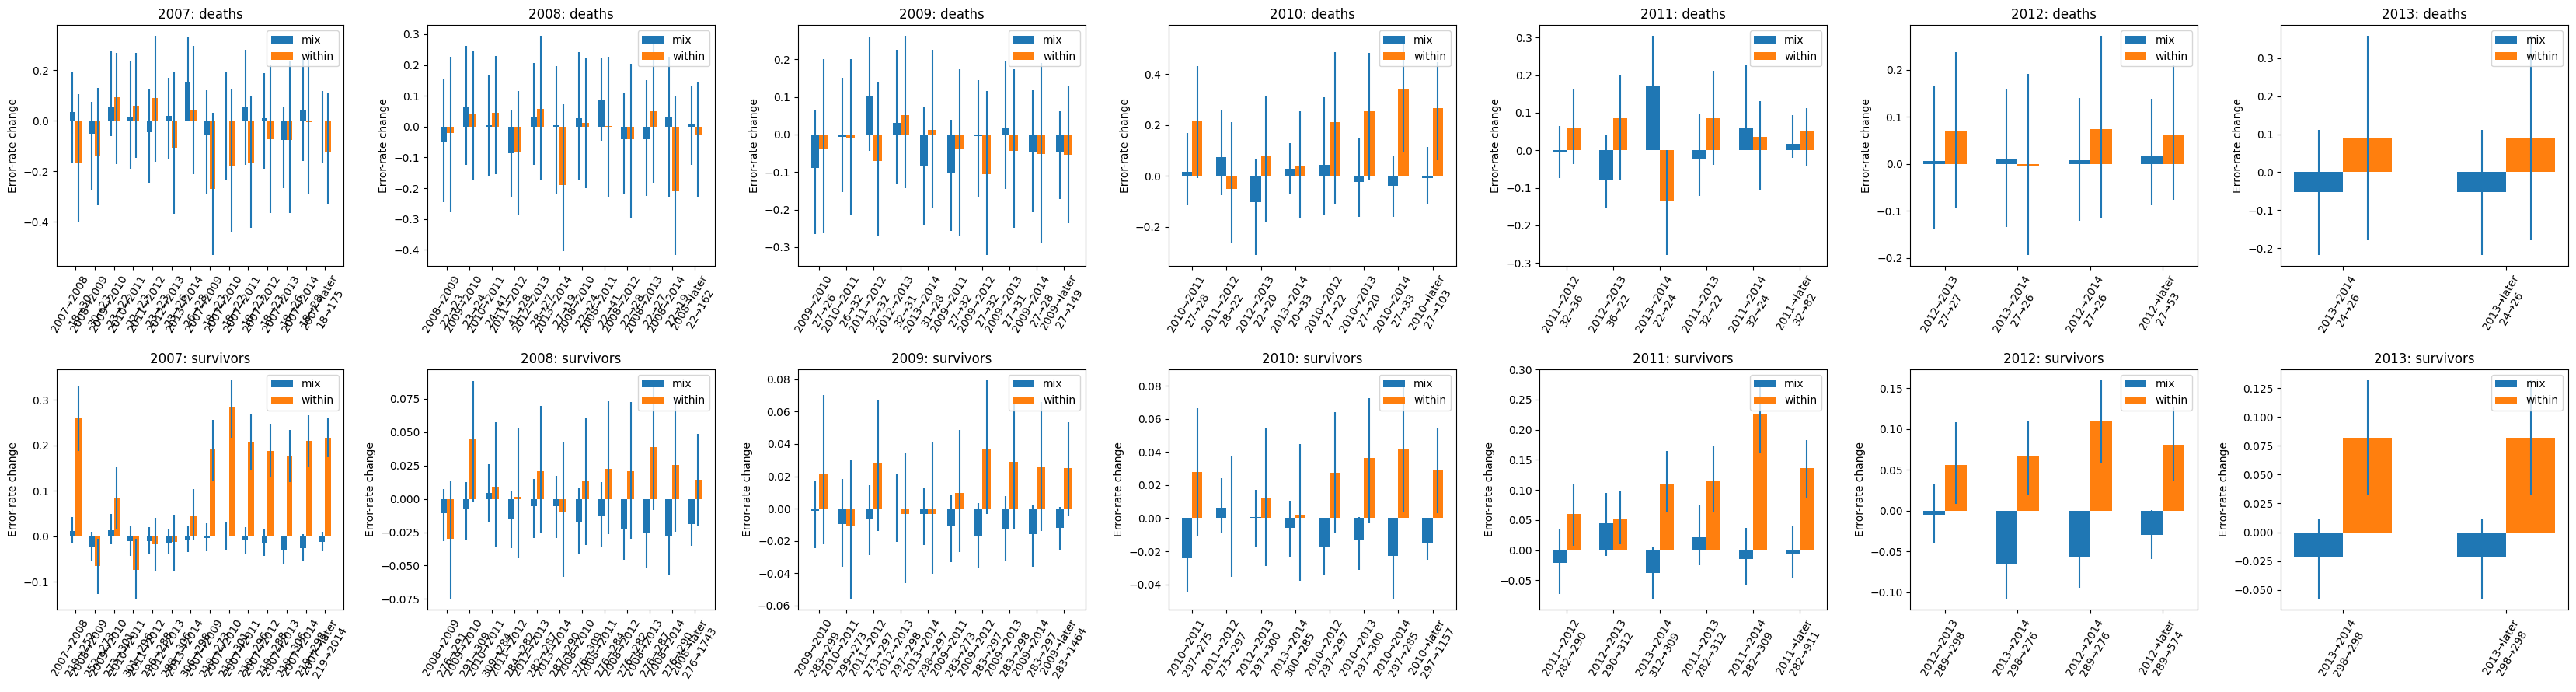

In [10]:
fig, axes = plt.subplots(2, len(cases), figsize=(4.75 * len(cases), 9), squeeze=False)
for col, case in enumerate(cases):
    table = analysis[case['reference']]['length_split']
    for row, side in enumerate(('deaths', 'survivors')):
        ax = axes[row, col]
        if table.empty:
            ax.text(.5, .5, 'Stopped: missing reference timing', ha='center'); continue
        for offset, component in ((-.15, 'mix'), (.15, 'within')):
            part = table[(table['side'] == side) & (table['component'] == component)]
            x = np.arange(len(part)) + offset
            ax.bar(x, part['value'], width=.3, label=component); ax.vlines(x, part['low'], part['high'])
        ax.set_xticks(np.arange(len(part)), [f"{r.start}→{r.end}\n{int(r.start_denominator)}→{int(r.end_denominator)}" for r in part.itertuples()], rotation=60)
        ax.set(title=f"{case['reference']}: {side}", ylabel='Error-rate change'); ax.legend()
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_04_record_length_split.png', dpi=160); plt.show()

Read mix and within together: they add exactly to the observed error-rate change. The files retain empty-group patient counts and patient equivalents for every component. The exact-month death count table exposes what the quarter grouping combines; zero care months reflect observed death-only records, while genuinely absent timing would stop this section.


## 4. Which feature differences repeat on other patients?

Use all 500 features, once comparing errors with correct predictions at the same outcome and once at the same prediction. Entrants order the complete list; evaluation patients supply reference, later and consecutive-year contrasts with joint patient intervals. A same-outcome level partly follows from score-based group definitions, so read its change beside the same-prediction view.


In [11]:
feature_views = ('same_outcome_deaths', 'same_outcome_survivors', 'same_prediction_flagged', 'same_prediction_unflagged')
for case in cases:
    ref, results = case['reference'], analysis[case['reference']]
    for name in ('evaluation', 'entrants'):
        view = case['views'][name]; frame = view['frame']
        quantities = {str(feature): view['features'][:, j] for j, feature in enumerate(case['feature_names'])}
        weights = ep.row_weights(frame['patient_id'], bootstrap)
        profile, draws = ep.year_profile(frame, quantities, weights, case['threshold'], ref)
        contrasts = ep.profile_contrasts(profile, draws, ref)
        results[f'{name}_feature_contrasts'] = contrasts
        profile.to_csv(OUTPUT / f'{ref}_{name}_feature_profiles.csv', index=False)
        contrasts.to_csv(OUTPUT / f'{ref}_{name}_feature_contrasts.csv', index=False)

In [12]:
for case in cases:
    ref, results = case['reference'], analysis[case['reference']]
    entrants = results['entrants_feature_contrasts'].query("kind == 'difference' and end == 'later'")
    entrants = entrants[['quantity', 'view', 'value', 'low', 'high']].rename(columns={c: f'entrant_{c}' for c in ('value', 'low', 'high')})
    change = results['evaluation_feature_contrasts'].query("kind == 'change' and end == 'later'")
    ordered = change.merge(entrants, on=['quantity', 'view'], validate='one_to_one')
    levels = results['evaluation_feature_contrasts'].query("kind == 'difference'")
    for period, prefix in ((str(ref), 'evaluation_reference'), ('later', 'evaluation_later')):
        part = levels[levels['end'] == period][['quantity', 'view', 'value', 'low', 'high']]
        part = part.rename(columns={col: f'{prefix}_{col}' for col in ('value', 'low', 'high')})
        ordered = ordered.merge(part, on=['quantity', 'view'], validate='one_to_one')
    ordered = ordered.sort_values(['view', 'entrant_value', 'quantity'], ascending=[True, False, True], kind='stable')
    ordered.to_csv(OUTPUT / f'{ref}_all_500_feature_changes_entrant_order.csv', index=False)
    results['feature_changes'] = ordered

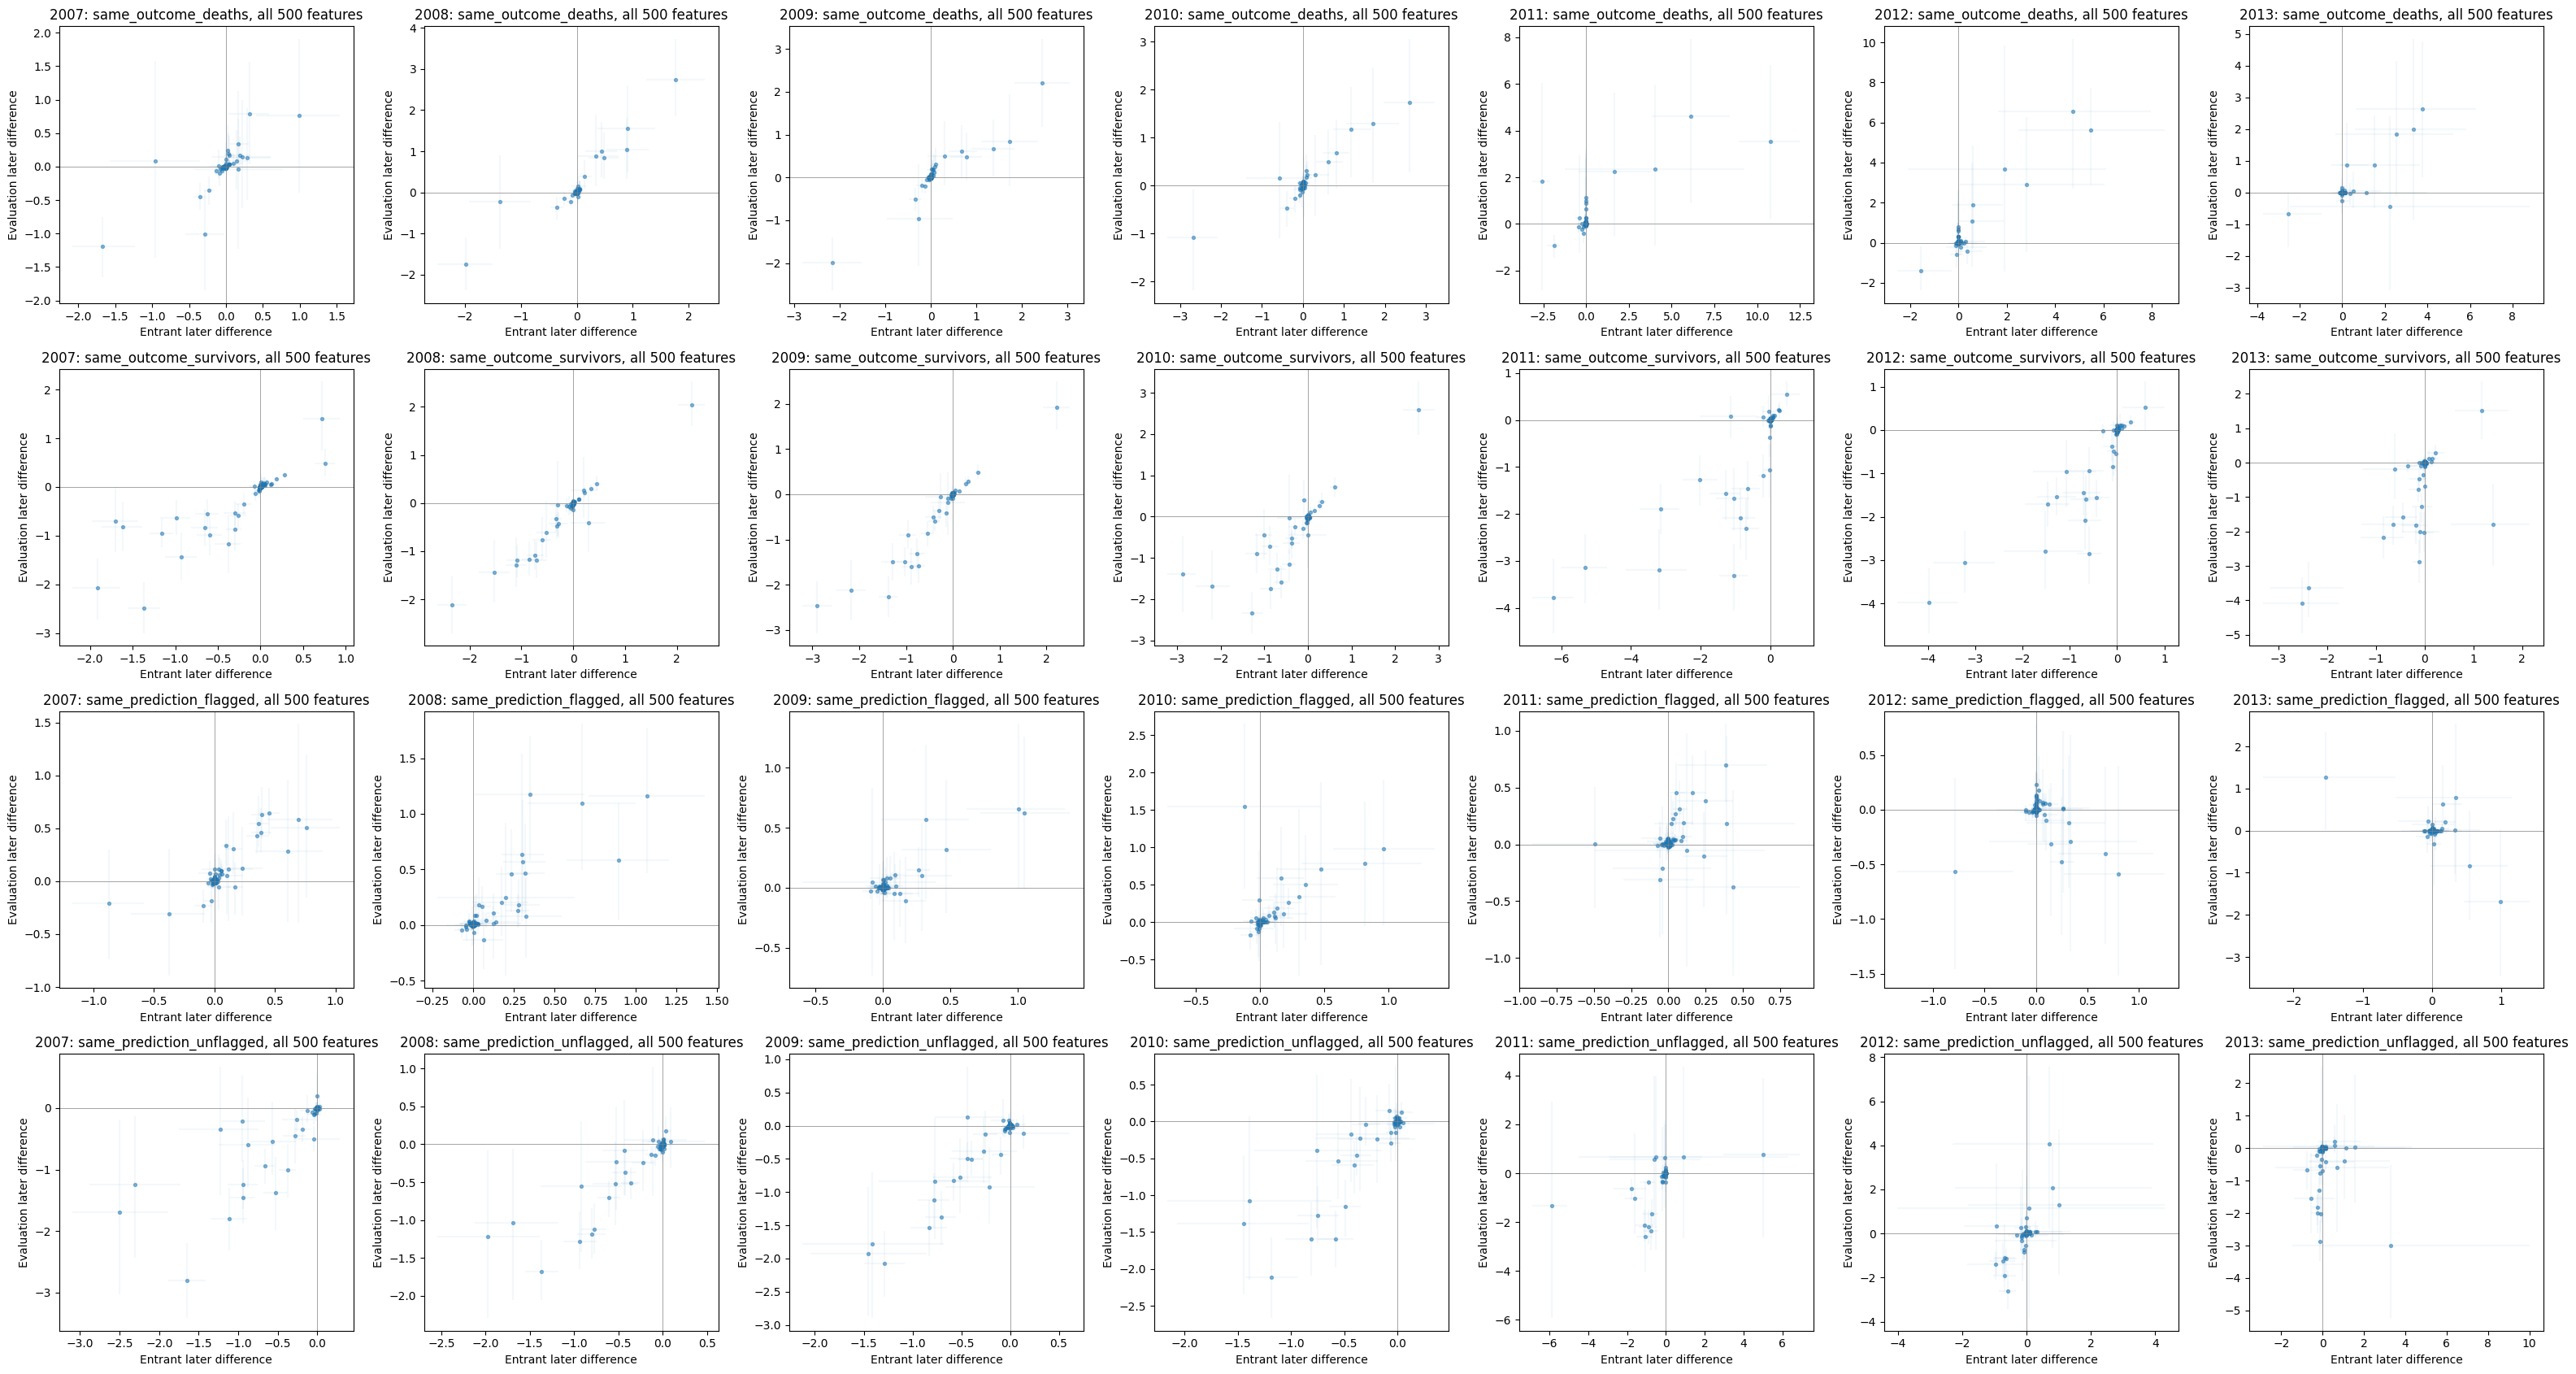

In [13]:
fig, axes = plt.subplots(4, len(cases), figsize=(4.5 * len(cases), 17), squeeze=False)
for col, case in enumerate(cases):
    ref, results = case['reference'], analysis[case['reference']]
    later = results['evaluation_feature_contrasts'].query("kind == 'difference' and end == 'later'")
    for row, view in enumerate(feature_views):
        part = results['feature_changes'].query('view == @view').merge(later.query('view == @view')[['quantity', 'value', 'low', 'high']], on='quantity', suffixes=('_change', '_later'))
        ax = axes[row, col]; x, y = part['entrant_value'], part['value_later']
        ax.scatter(x, y, s=8, alpha=.5)
        ax.hlines(y, part['entrant_low'], part['entrant_high'], alpha=.05); ax.vlines(x, part['low_later'], part['high_later'], alpha=.05)
        ax.axhline(0, color='grey', lw=.5); ax.axvline(0, color='grey', lw=.5)
        ax.set(title=f'{ref}: {view}, all {len(part)} features', xlabel='Entrant later difference', ylabel='Evaluation later difference')
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_05_all_features.png', dpi=160); plt.show()

Every feature appears; there is no top-k or support filter. Complete files include all yearly differences, consecutive-year changes and reference-to-later changes, with the underlying group counts and defined/undefined bootstrap draws. Entrants have no reference-year change estimate and never determine an evaluation contrast.


## 5. Which existing concepts changed, and do features imply the same change?

For each of the 62 frozen concepts, profile rule membership, activation, agreement and saved log-odds sensitivity within every prediction group. Fit ridge only on reference evaluation patients, with patient-level outer folds and training-only scaling and penalty selection inside each fold; every annual prediction uses the model that excluded that patient. These patient intervals condition on the fitted ridge, whose reference held-out RMSE supplies a scale.


In [14]:
for case in cases:
    ref, view, results = case['reference'], case['views']['evaluation'], analysis[case['reference']]
    frame, all_profiles, all_contrasts, all_splits, all_rates, ridge_audits = view['frame'], [], [], [], [], []
    for concept in case['concepts']:
        key, arrays = concept['record']['concept'], concept['arrays']
        ridge = ep.crossfit_ridge(view['features'], arrays['activation'], frame['patient_id'].to_numpy(),
                                 frame['year'].to_numpy(), ref, SEED, RIDGE_FOLDS, RIDGE_ALPHAS)
        if 'sensitivity_all_negatives' not in arrays and any(s == 'measured' for s in concept['direction_fit']['fit_status']):
            raise ValueError(f'{key}: measured direction but no saved sensitivity')
        sensitivity = arrays.get('sensitivity_all_negatives', np.full((len(frame), 50), np.nan))  # no direction: undefined, counted
        quantities = {'activation': arrays['activation'], 'rule_membership': arrays['in_R'].astype(float),
                      'activated': arrays['in_A'].astype(float), 'ridge_activation': ridge['prediction'],
                      'activation_given_rule': np.where(arrays['in_R'], arrays['in_A'].astype(float), np.nan),
                      'log_odds_sensitivity': ep.log_odds_sensitivity(sensitivity, frame['probability'])}
        profile, draws = ep.year_profile(frame, quantities, results['weights'], case['threshold'], ref)
        all_profiles.append(profile.assign(concept=key)); all_contrasts.append(ep.profile_contrasts(profile, draws, ref).assign(concept=key))
        all_splits.append(ep.rate_splits(frame, arrays['in_R'], results['weights'], case['threshold'], ref, results['risks']).assign(concept=key))
        all_rates.append(ep.rule_error_rates(frame, arrays['in_R'], results['weights'], case['threshold'], ref, results['risks']).assign(concept=key))
        ridge_audits.append(ridge['audit'].assign(concept=key, reference_rmse=float(ridge['reference_rmse'])))
    for name, parts in (('concept_profiles', all_profiles), ('concept_contrasts', all_contrasts), ('concept_splits', all_splits), ('concept_rates', all_rates), ('ridge_audit', ridge_audits)):
        results[name] = pd.concat(parts, ignore_index=True); results[name].to_csv(OUTPUT / f'{ref}_{name}.csv', index=False)

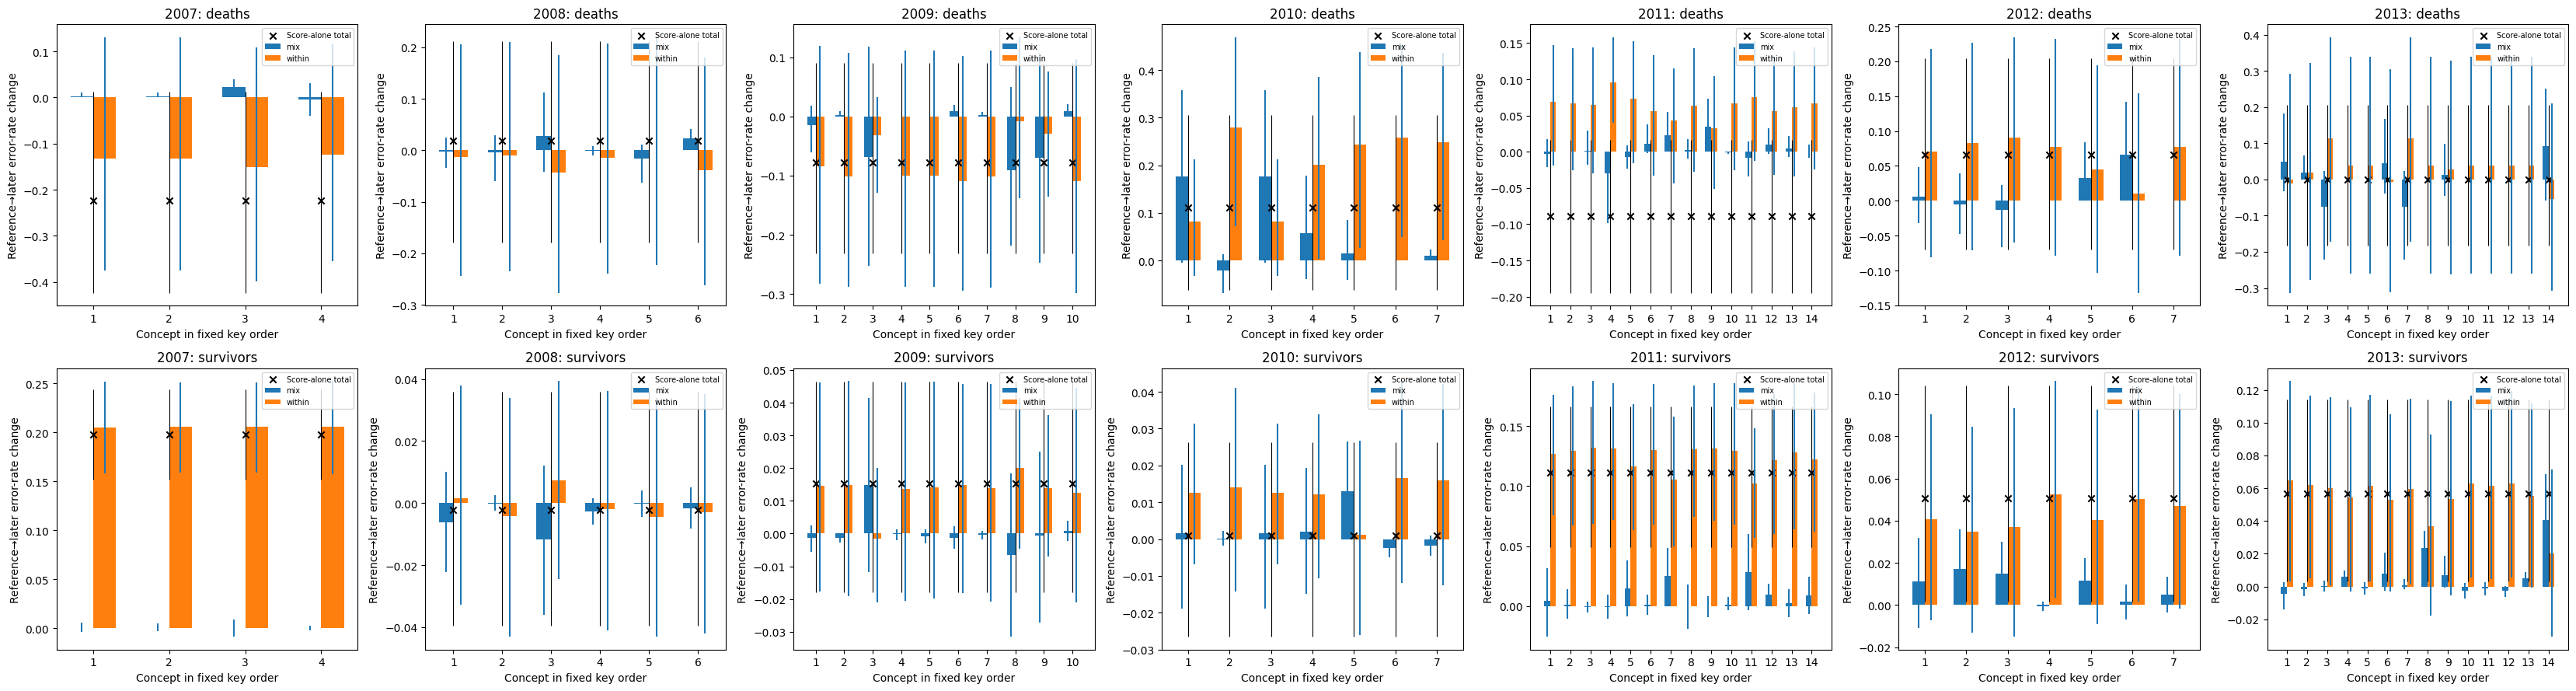

In [15]:
fig, axes = plt.subplots(2, len(cases), figsize=(4.75 * len(cases), 9), squeeze=False)
for col, case in enumerate(cases):
    ref, table = case['reference'], analysis[case['reference']]['concept_splits']
    ref_text = str(ref)
    for row, side in enumerate(('deaths', 'survivors')):
        ax = axes[row, col]; selected = table.query("side == @side and start == @ref_text and end == 'later'")
        for offset, component in ((-.15, 'mix'), (.15, 'within')):
            part = selected.query("version == 'observed' and component == @component").sort_values('concept')
            x = np.arange(len(part)) + offset; ax.bar(x, part['value'], .3, label=component); ax.vlines(x, part['low'], part['high'])
        expected = selected.query("version == 'score_alone' and component == 'change'").sort_values('concept')
        ax.scatter(np.arange(len(expected)), expected['value'], marker='x', color='black', label='Score-alone total')
        ax.vlines(np.arange(len(expected)), expected['low'], expected['high'], color='black', lw=.8)
        ax.set_xticks(np.arange(len(part)), [str(i+1) for i in range(len(part))]); ax.set(title=f'{ref}: {side}', xlabel='Concept in fixed key order', ylabel='Reference→later error-rate change'); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_06_concept_splits.png', dpi=160); plt.show()

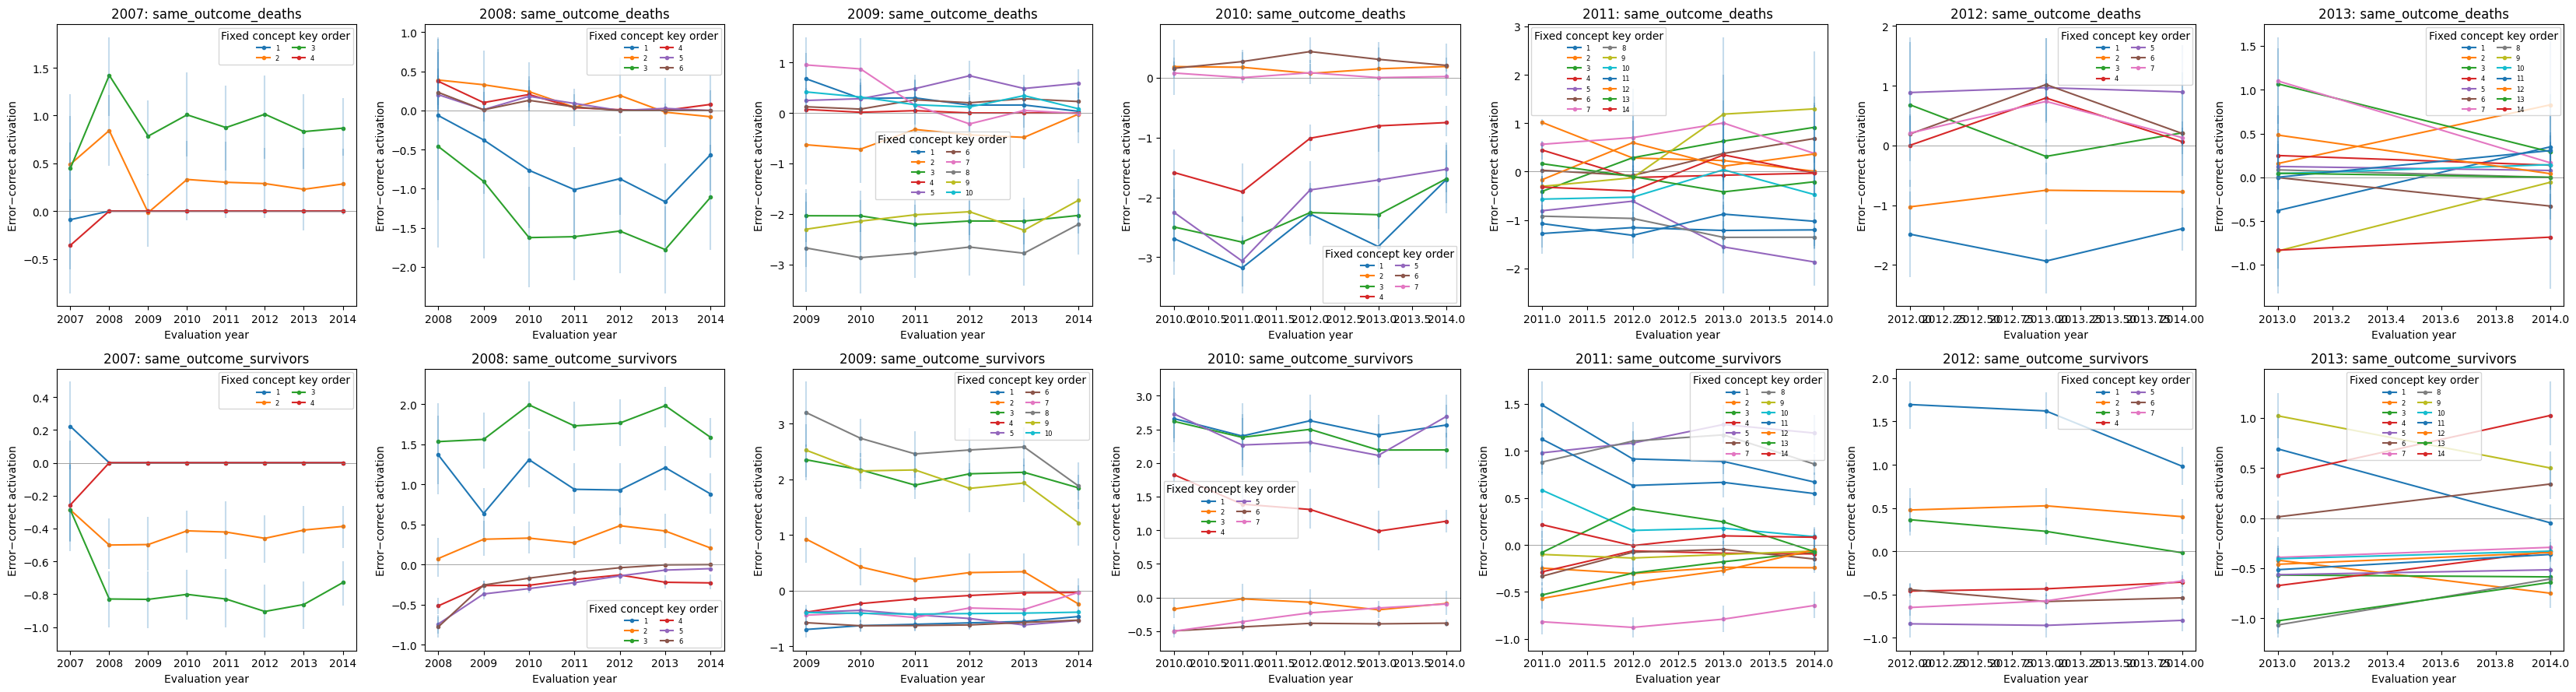

In [16]:
fig, axes = plt.subplots(2, len(cases), figsize=(4.75 * len(cases), 9), squeeze=False)
for col, case in enumerate(cases):
    ref, table = case['reference'], analysis[case['reference']]['concept_contrasts']
    for row, view in enumerate(('same_outcome_deaths', 'same_outcome_survivors')):
        ax = axes[row, col]; selected = table.query("view == @view and kind == 'difference' and quantity == 'activation' and end != 'later'")
        for number, (key, part) in enumerate(selected.groupby('concept', sort=True), 1):
            x = part['end'].astype(int); ax.plot(x, part['value'], marker='.', label=str(number)); ax.vlines(x, part['low'], part['high'], alpha=.25)
        ax.axhline(0, color='grey', lw=.5); ax.set(title=f'{ref}: {view}', xlabel='Evaluation year', ylabel='Error−correct activation'); ax.legend(title='Fixed concept key order', fontsize=6, ncol=2)
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_10_concept_error_profiles.png', dpi=160); plt.show()

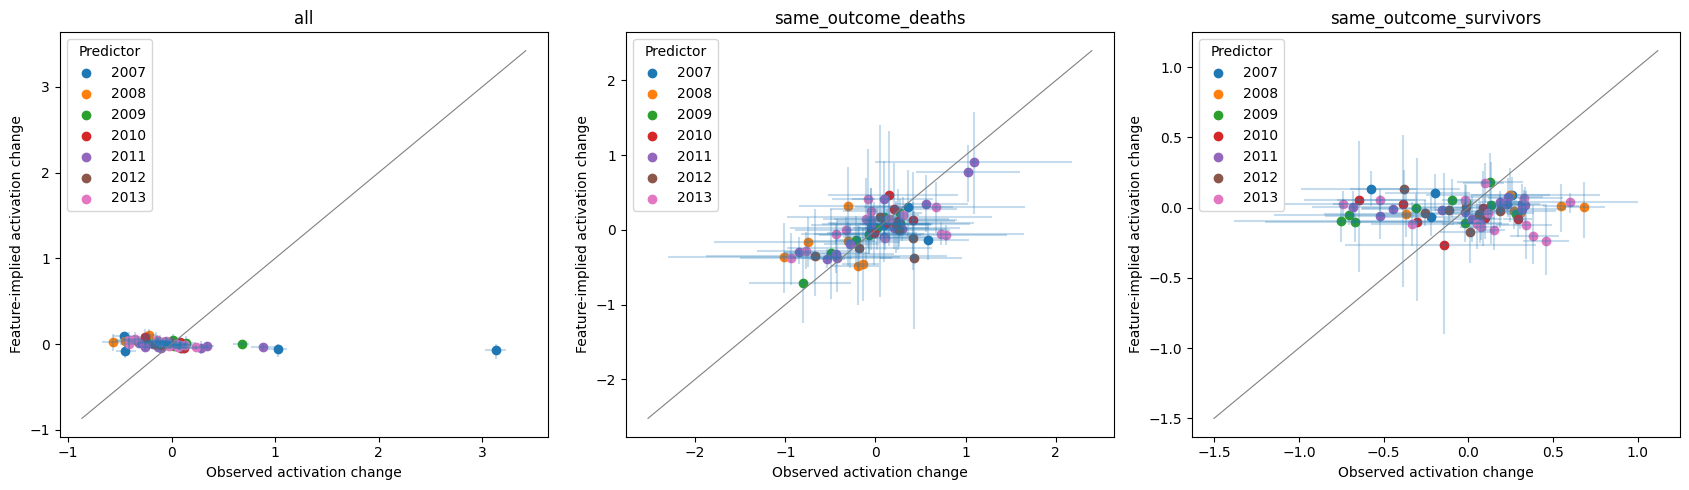

In [17]:
agreement_tables = []
fig, axes = plt.subplots(1, 3, figsize=(17, 5), squeeze=False)
for case in cases:
    ref, table = case['reference'], analysis[case['reference']]['concept_contrasts']
    for col, view in enumerate(('all', 'same_outcome_deaths', 'same_outcome_survivors')):
        selected = table.query("view == @view and kind == 'change' and end == 'later'")
        observed = selected.query("quantity == 'activation'"); implied = selected.query("quantity == 'ridge_activation'")
        part = observed.merge(implied, on=['reference', 'concept', 'view', 'start', 'end'], suffixes=('_observed', '_implied'), validate='one_to_one')
        agreement_tables.append(part); ax = axes[0, col]
        ax.scatter(part['value_observed'], part['value_implied'], label=str(ref))
        ax.hlines(part['value_implied'], part['low_observed'], part['high_observed'], alpha=.25); ax.vlines(part['value_observed'], part['low_implied'], part['high_implied'], alpha=.25)
        ax.set(title=view, xlabel='Observed activation change', ylabel='Feature-implied activation change'); ax.legend(title='Predictor')
for ax in axes.ravel():
    limits = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]; ax.plot(limits, limits, color='grey', lw=.8)
pd.concat(agreement_tables, ignore_index=True).to_csv(OUTPUT / 'feature_concept_agreement.csv', index=False)
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_11_feature_concept_agreement.png', dpi=160); plt.show()

Read the all-evaluation comparison first; error-minus-correct differences are thin on the death side, especially for the 2011 and 2012 predictors. Fifty attempted direction positions are preserved for every frozen concept; measured counts per concept are in the fixed-order coverage file. An unavailable sensitivity is reported with counts and never becomes zero. Rule agreement conditions on actual rule membership; a rule with no deaths retains its counts and non-estimable rates. The year input also moves embeddings.


In [18]:
concept_order, predefined = [], []
for case in cases:
    ref = case['reference']
    for number, concept in enumerate(case['concepts'], 1):
        fit = concept['direction_fit']
        concept_order.append(dict(reference=ref, order=number, concept=concept['record']['concept'],
                                  measured_direction_fits=sum(s == 'measured' for s in fit['fit_status']),
                                  attempted_direction_fits=50, matching_fit_patients=fit['matching'], nonmatching_fit_patients=fit['nonmatching']))
    table = analysis[ref]['concept_contrasts'].query("quantity == 'activation' and kind == 'change' and view in ['same_outcome_deaths', 'same_outcome_survivors']")
    for (start, end, view), part in table.groupby(['start', 'end', 'view']):
        defined = part['low'].notna() & part['high'].notna()
        predefined.append(dict(reference=ref, start=start, end=end, view=view, concepts=len(part),
                               defined_intervals=int(defined.sum()), undefined_intervals=int((~defined).sum()),
                               excluding_zero=int(((part['low'] > 0) | (part['high'] < 0)).sum()), expected_at_five_percent=.05*defined.sum()))
pd.DataFrame(concept_order).to_csv(OUTPUT / 'existing_concept_fixed_order_and_fit_coverage.csv', index=False)
pd.DataFrame(predefined).to_csv(OUTPUT / 'predefined_concept_interval_counts.csv', index=False)

Interval-exclusion counts are given only for the 62 pre-specified concepts, beside 5% of the number of defined intervals. These concepts and predictors share patients and internal directions; that comparison is descriptive, and agreement across predictors is not replication. Figure concept numbers map to full frozen keys in the fixed-order coverage file.


## 6. Which groups newly mark the errors?

Three searches, all chosen on entrants and reported on evaluation patients. **6a** scans all 864 frozen factors (three SAE seeds): each factor's *error link* is the rank correlation between its activation and a residual target over patient-years, given for the plain target (outcome minus predicted risk), the score-alone target (outcome minus this year's two-number score fit) and the adjusted target (score-alone residual minus its mean within the same year and exact months with care). Plain answers the question; the other two say whether the factor adds anything beyond the score and record length. Every factor also gets a feature description (6a), **6b** looks for feature-defined slices directly, and **6c** gives every new rule a sensitivity with the frozen recipe.

Entrants have no reference year, so they only order and choose; "emerging" (reference → later change) is read on evaluation patients. 864 factors are not 864 independent looks: the effective number of directions and the number of distinct rules are printed. Finding nothing does not show that nothing emerged.

In [19]:
tick = time.perf_counter()
for case in cases:
    ref, results, evaluation, entrants = case['reference'], analysis[case['reference']], case['views']['evaluation'], case['views']['entrants']
    if not case['timing_ready']:
        raise ValueError(f'{ref}: incomplete reference-year timing; the record-length-adjusted choosing target cannot be formed')
    keys, codes = ep.factor_columns(evaluation['codes'])
    names = [f'{seed}:{k}' for seed, k in keys]
    entrant_weights = ep.row_weights(entrants['frame']['patient_id'], bootstrap)
    entrant_risks, _, entrant_fits = ep.annual_benchmarks(entrants['frame'], entrant_weights, ref)
    links = []
    for name, view, weights, risks in (('evaluation', evaluation, results['weights'], results['risks']),
                                       ('entrants', entrants, entrant_weights, entrant_risks)):
        targets = ep.choosing_targets(view['frame'], risks, weights)
        links.append(ep.factor_links(ep.factor_columns(view['codes'])[1], names, targets, weights, view['frame'], ref).assign(set=name))
    activity = {f'{n}|mean_activation': codes[:, j] for j, n in enumerate(names)}
    activity |= {f'{n}|share_above_zero': (codes[:, j] > 0).astype(float) for j, n in enumerate(names)}
    profile, draws = ep.year_profile(evaluation['frame'], activity, results['weights'], case['threshold'], ref)
    change = ep.summarize_matrix(np.column_stack([draws[('later', 'all', q)] - draws[(str(ref), 'all', q)] for q in activity]))
    del draws
    results.update(factor_names=names, factor_links=pd.concat(links, ignore_index=True), factor_activity=profile,
                   factor_activity_change=change.assign(reference=ref, quantity=list(activity), period=f'{ref}→later'),
                   effective_dimension=ep.effective_dimension(codes))
    for name in ('factor_links', 'factor_activity', 'factor_activity_change'):
        results[name].to_csv(OUTPUT / f'{ref}_{name}.csv', index=False)
    entrant_fits.to_csv(OUTPUT / f'{ref}_entrant_score_fits.csv', index=False)
    print(f"{ref}: {len(names)} factors; effective number of independent directions (participation ratio, evaluation patients) = {results['effective_dimension']:.2f}")
timings['6a error links and activity'] = time.perf_counter() - tick

2007: 864 factors; effective number of independent directions (participation ratio, evaluation patients) = 2.97


2008: 864 factors; effective number of independent directions (participation ratio, evaluation patients) = 6.14


2009: 864 factors; effective number of independent directions (participation ratio, evaluation patients) = 5.96


2010: 864 factors; effective number of independent directions (participation ratio, evaluation patients) = 6.43


2011: 864 factors; effective number of independent directions (participation ratio, evaluation patients) = 6.05


2012: 864 factors; effective number of independent directions (participation ratio, evaluation patients) = 6.46


2013: 864 factors; effective number of independent directions (participation ratio, evaluation patients) = 6.11


**Rule for every factor.** A small tree (at most 3 conditions, size by patient-grouped cross-validated pruning, no hand-set leaf size) predicts the factor's activation from the 500 features on later entrants; the leaf with the highest mean activation is the factor's rule. No activation cutoff is used — a stated departure from the frozen study, whose "factor active" cutoff came from a per-concept rule search. If pruning keeps no split the factor has "no feature description" and no rule. Beside every rule: entrant and evaluation counts in the rule, the share of activation variance the tree explains on later evaluation patients, and mean activation inside vs outside the rule per year (point values). For the 62 frozen medoid factors, overlap with the frozen rule: high overlap means this description recovers the frozen rule; low overlap does not mean a poor description (year, patients and target all differ). Rules are merged only when their definitions are identical; the list of factors behind each rule is kept.

In [20]:
tick = time.perf_counter()
for case in cases:
    ref, results, evaluation, entrants = case['reference'], analysis[case['reference']], case['views']['evaluation'], case['views']['entrants']
    keys, entrant_codes = ep.factor_columns(entrants['codes']); eval_codes = ep.factor_columns(evaluation['codes'])[1]
    fits = ep.describe_factors(entrants['features'], entrant_codes, entrants['frame']['patient_id'].to_numpy(), TREE_FOLDS, SEED, WORKERS)
    years = evaluation['frame']['year'].to_numpy(); later = years > ref
    frozen = {(int(c['record']['seed']), int(c['record']['factor'])): c for c in case['concepts']}
    rows, rules = [], {}
    for j, (key, name, fit) in enumerate(zip(keys, results['factor_names'], fits)):
        row, rule = dict(reference=ref, factor=name, status=fit['status'], tree_fits=fit['fit_count'], leaves=fit.get('leaves'),
                         cv_loss=fit.get('cv_loss')), fit.get('factor_rule')
        if rule:
            inside = ep.rule_mask(rule, evaluation['features'])
            rules.setdefault(ep.rule_key(rule), {'rule': rule, 'factors': []})['factors'].append(name)
            row.update(rule=ep.rule_key(rule), rule_text=ep.rule_text(rule, case['feature_names']),
                       entrant_rows_in_rule=int(ep.rule_mask(rule, entrants['features']).sum()),
                       evaluation_later_rows_in_rule=int((inside & later).sum()),
                       entrant_patients_in_rule=entrants['frame']['patient_id'][ep.rule_mask(rule, entrants['features'])].nunique(),
                       evaluation_later_patients_in_rule=evaluation['frame']['patient_id'][inside & later].nunique(),
                       evaluation_later_r2=ep.heldout_r2(fit['tree'].predict(evaluation['features'][later]), eval_codes[later, j]))
            for year in sorted(np.unique(years)):
                for side, mask in (('inside', inside), ('outside', ~inside)):
                    at = (years == year) & mask
                    row[f'{side}_mean_activation_{year}'] = eval_codes[at, j].mean() if at.any() else np.nan
                    row[f'{side}_rows_{year}'] = int(at.sum())
            if key in frozen:
                old = frozen[key]['arrays']['in_R']
                row.update(frozen_rule_rows=int(old.sum()), overlap_rows=int((old & inside).sum()),
                           overlap_jaccard=(old & inside).sum() / (old | inside).sum() if (old | inside).any() else np.nan)
        rows.append(row)
    results['factor_descriptions'], results['factor_rules'] = pd.DataFrame(rows), rules
    results['factor_descriptions'].to_csv(OUTPUT / f'{ref}_factor_descriptions.csv', index=False)
    print(f"{ref}: {sum(f['fit_count'] for f in fits)} tree fits (incl. cross-validation and pruning); "
          f"{len(rules)} distinct factor rules from {sum(r is not None and len(r) > 0 for r in (f.get('factor_rule') for f in fits))} described factors; "
          f"{sum(f['status'] == 'no feature description' for f in fits)} factors with no feature description")
    display(results['factor_descriptions'].query('frozen_rule_rows == frozen_rule_rows')[['factor', 'rule_text', 'frozen_rule_rows', 'overlap_rows', 'overlap_jaccard']]
            if 'frozen_rule_rows' in results['factor_descriptions'] else 'No frozen medoid factor received a rule')
timings['6a factor descriptions'] = time.perf_counter() - tick

2007: 33662 tree fits (incl. cross-validation and pruning); 480 distinct factor rules from 619 described factors; 245 factors with no feature description


,factor,rule_text,frozen_rule_rows,overlap_rows,overlap_jaccard
654,215:78,DIAGN_N180 > 9.5 and EVENT_C1DIALISE_HD > 11.5...,315.0,114.0,0.265116
838,215:262,EVENT_C1DIALISE_HD > 11.5 and EVENT_C1DIALISE_...,70.0,51.0,0.301775


2008: 40582 tree fits (incl. cross-validation and pruning); 655 distinct factor rules from 831 described factors; 33 factors with no feature description


,factor,rule_text,frozen_rule_rows,overlap_rows,overlap_jaccard
218,42:218,EVENT_C1DIALISE_HD > 1.5 and EVENT_C1DIALISE_H...,296.0,270.0,0.912162
279,42:279,DIAGN_Z940 > 2.5 and EVENT_C1DIALISE_HD <= 1.5...,289.0,274.0,0.948097
283,42:283,EVENT_C1DIALISE_HD > 11.5 and EVENT_c2MED_ERIT...,165.0,165.0,0.964912
730,215:154,EVENT_C1DIALISE_HD > 11.5 and EVENT_c2MED_ERIT...,364.0,316.0,0.793970
760,215:184,EVENT_c2MED_ERITRO > 0.5 and EVENT_C1DIALISE_H...,61.0,61.0,0.148780
809,215:233,EVENT_C1DIALISE_HD > 2.5 and EVENT_C1DIALISE_H...,192.0,166.0,0.864583


2009: 42480 tree fits (incl. cross-validation and pruning); 675 distinct factor rules from 861 described factors; 3 factors with no feature description


,factor,rule_text,frozen_rule_rows,overlap_rows,overlap_jaccard
157,42:157,EVENT_C1DIALISE_HD > 4.5 and DIAGN_Z940 > 0.5 ...,67.0,9.0,0.130435
223,42:223,DIAGN_Z940 > 0.5 and EVENT_C1DIALISE_HD <= 0.5...,340.0,268.0,0.774566
235,42:235,DIAGN_N180 <= 7.5 and EVENT_C1DIALISE_HD > 0.5...,107.0,107.0,0.914530
359,135:71,EVENT_c2MED_ERITRO <= 0.5 and EVENT_C1DIALISE_...,90.0,67.0,0.563025
581,215:5,EVENT_C1DIALISE_HD > 10.5 and DIAGN_N180 > 10....,306.0,190.0,0.562130
617,215:41,EVENT_c3ACESSO_CT > 0.5 and EVENT_C1DIALISE_HD...,247.0,47.0,0.188000
695,215:119,EVENT_C1DIALISE_HD > 0.5 and EVENT_C1DIALISE_H...,211.0,161.0,0.763033
714,215:138,EVENT_C1DIALISE_HD > 8.5 and EVENT_C1DIALISE_H...,41.0,16.0,0.130081
733,215:157,EVENT_c2MED_MICOF > 3.5 and DIAGN_N180 <= 0.5 ...,79.0,55.0,0.273632
796,215:220,DIAGN_N180 > 9.5 and EVENT_c2MED_ERITRO > 3.5 ...,169.0,167.0,0.491176


... (4 outputs left out)

2012: 43355 tree fits (incl. cross-validation and pruning); 688 distinct factor rules from 864 described factors; 0 factors with no feature description


,factor,rule_text,frozen_rule_rows,overlap_rows,overlap_jaccard
118,42:118,DIAGN_N180 <= 7.5 and EVENT_C1DIALISE_HD > 0.5...,54.0,52.0,0.590909
408,135:120,EVENT_c2MED_ERITRO > 8.5 and EVENT_c2MED_HIDFE...,69.0,32.0,0.313725
439,135:151,EVENT_c2MED_ERITRO > 7.5 and EVENT_C1DIALISE_H...,66.0,41.0,0.401961
478,135:190,EVENT_c2MED_MICOF > 0.5 and EVENT_c5TX_TX > 1.5,5.0,0.0,0.000000
507,135:219,EVENT_C1DIALISE_HD > 0.5 and DIAGN_N180 <= 5.5...,65.0,33.0,0.366667
810,215:234,EVENT_C1DIALISE_HD > 3.5 and DIAGN_N180 <= 11....,107.0,63.0,0.543103
828,215:252,EVENT_C1DIALISE_HD > 10.5 and DIAGN_N180 > 9.5...,138.0,120.0,0.628272


2013: 41843 tree fits (incl. cross-validation and pruning); 591 distinct factor rules from 845 described factors; 19 factors with no feature description


,factor,rule_text,frozen_rule_rows,overlap_rows,overlap_jaccard
119,42:119,DIAGN_N180 > 4.5 and DIAGN_N180 <= 11.5 and DI...,151.0,151.0,0.949686
186,42:186,DIAGN_N180 > 11.5,12.0,12.0,0.073171
216,42:216,EVENT_C1DIALISE_HD > 0.5 and DIAGN_N180 <= 1.5...,70.0,11.0,0.139241
357,135:69,EVENT_c2MED_ERITRO > 7.5 and EVENT_c2MED_HIDFE...,76.0,0.0,0.000000
495,135:207,DIAGN_N180 > 11.5 and EVENT_C1DIALISE_HD > 7,124.0,124.0,0.953846
508,135:220,EVENT_C1DIALISE_HD > 0.5 and DIAGN_N180 <= 1.5...,35.0,9.0,0.243243
716,215:140,DIAGN_N180 <= 0.5 and EVENT_C1DIALISE_HD <= 0....,98.0,87.0,0.617021
727,215:151,EVENT_c2MED_HIDFE > 0.5 and EVENT_C1DIALISE_HD...,43.0,22.0,0.112821
738,215:162,DIAGN_N180 <= 11.5 and DIAGN_Z944 > 8.5,14.0,0.0,0.000000
792,215:216,DIAGN_N180 > 2.5 and EVENT_c2MED_HIDFE <= 0.5 ...,88.0,2.0,0.011905


**6b. Residual slices.** One shallow tree per predictor on later entrants, features only, at most 3 conditions per slice (a readability choice), size by patient-grouped cross-validated pruning. Target: outcome minus score-alone risk, minus its mean within the same year and exact months with care; inside cross-validation both are fitted on training patients only, and a held-out month never seen in training stays undefined. Every leaf is a slice. Reported on evaluation patients for every year including the reference year: share, observed minus predicted mortality (plain) beside observed minus score-alone risk, missed deaths and false alarms as counts, separately for newcomers (first year) and returning patients. Limitation: entrants all joined after the reference year, so a group existing only among long-standing patients can be missed here.

In [21]:
tick = time.perf_counter()
display(study['composition'])
for case in cases:
    ref, results, evaluation, entrants = case['reference'], analysis[case['reference']], case['views']['evaluation'], case['views']['entrants']
    if not case['timing_ready']:
        raise ValueError(f'{ref}: incomplete reference-year timing; the record-length-adjusted choosing target cannot be formed')
    frame = entrants['frame']
    fit = ep.fit_tree(entrants['features'], None, frame['patient_id'].to_numpy(), case['feature_names'], TREE_FOLDS, SEED, frame=frame)
    chosen_target = ep.training_target(frame, frame)[0]
    slices, reports, overlaps = [], [], []
    for number, rule in enumerate(fit['rules'], 1):
        name, member = f'slice {number}', ep.rule_mask(rule, evaluation['features'])
        entrant_member = ep.rule_mask(rule, entrants['features'])
        slices.append(dict(reference=ref, slice=name, rule=ep.rule_key(rule), rule_text=ep.rule_text(rule, case['feature_names']),
                           entrant_rows=int(entrant_member.sum()), entrant_mean_target=float(np.nanmean(chosen_target[entrant_member])),
                           evaluation_rows=int(member.sum())))
        reports.append(ep.slice_report(evaluation['frame'], member, results['weights'], results['risks'], case['threshold'], ref).assign(slice=name))
        later = evaluation['frame']['year'].to_numpy() > ref
        for concept in case['concepts']:
            existing = concept['arrays']['in_R']
            overlaps.append(dict(reference=ref, slice=name, concept=concept['record']['concept'], later_slice_rows=int((member & later).sum()),
                                 later_rule_rows=int((existing & later).sum()), later_both=int((member & existing & later).sum())))
    print(f"{ref}: {fit['status']}; {len(slices)} slices; {fit['fit_count']} tree fits, {fit['nuisance_fit_count']} score fits inside cross-validation")
    results['slice_fit'] = fit
    results['slice_status'] = ('No feature-defined group found' if fit['status'] == 'no feature description'
                               else f"Slice selection unavailable ({fit['status']}) — not evidence that no group exists" if not slices else fit['status'])
    results['slices'] = pd.DataFrame(slices, columns=['reference', 'slice', 'rule', 'rule_text', 'entrant_rows', 'entrant_mean_target', 'evaluation_rows'])
    results['slices'] = results['slices'].sort_values('entrant_mean_target', ascending=False, kind='stable')
    results['slice_rules'] = dict(zip([s['slice'] for s in slices], fit['rules']))
    results['slice_reports'] = pd.concat(reports, ignore_index=True) if reports else pd.DataFrame()
    for name, table in (('slices', results['slices']), ('slice_reports', results['slice_reports']),
                        ('slice_existing_rule_overlap', pd.DataFrame(overlaps)), ('slice_cv_diagnostics', fit['cv_diagnostics'])):
        table.to_csv(OUTPUT / f'{ref}_{name}.csv', index=False)
    display(results['slices'] if slices else results['slice_status'])
timings['6b slices'] = time.perf_counter() - tick

,reference,set,year,rows,patients,first_year_rows,entrant_rows,mean_active_months,mortality,original_fitting_entrant_rows,excluded_gapreturner_rows,excluded_context_exposed_rows,chosen_context_exposed_rows
0,2007,evaluation,2007,237,237,237,0,8.324895,0.075949,NaN,NaN,NaN,NaN
1,2007,evaluation,2008,282,282,90,90,8.113475,0.106383,NaN,NaN,NaN,NaN
2,2007,evaluation,2009,296,296,67,131,8.351351,0.077703,NaN,NaN,NaN,NaN
3,2007,evaluation,2010,323,323,67,167,8.071207,0.068111,NaN,NaN,NaN,NaN
4,2007,evaluation,2011,319,319,83,221,8.401254,0.072100,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,2012,direction_fit,2012,159,159,18,0,8.698113,0.088050,NaN,NaN,NaN,NaN
66,2013,evaluation,2013,322,322,49,0,8.624224,0.074534,NaN,NaN,NaN,NaN
67,2013,evaluation,2014,324,324,42,64,9.191358,0.080247,NaN,NaN,NaN,NaN
68,2013,entrants,2014,246,246,246,246,4.772358,0.130081,443.0,197.0,109.0,0.0


2007: described; 4 slices; 49 tree fits, 42 score fits inside cross-validation


,reference,slice,rule,rule_text,entrant_rows,entrant_mean_target,evaluation_rows
2,2007,slice 3,"[[39,"">"",""0x1.0000000000000p-1""],[103,""<="",""0x...",DIAGN_A419 <= 0.5 and DIAGN_J960 > 0.5,35,0.253191,2
3,2007,slice 4,"[[103,"">"",""0x1.0000000000000p-1""]]",DIAGN_A419 > 0.5,95,0.196774,20
1,2007,slice 2,"[[1,"">"",""0x1.4000000000000p+1""],[39,""<="",""0x1....",DIAGN_A419 <= 0.5 and DIAGN_J960 <= 0.5 and EV...,3935,0.015168,1064
0,2007,slice 1,"[[1,""<="",""0x1.4000000000000p+1""],[39,""<="",""0x1...",DIAGN_A419 <= 0.5 and DIAGN_J960 <= 0.5 and EV...,5111,-0.017070,1340


2008: described; 8 slices; 48 tree fits, 36 score fits inside cross-validation


,reference,slice,rule,rule_text,entrant_rows,entrant_mean_target,evaluation_rows
7,2008,slice 8,"[[0,"">"",""0x1.3000000000000p+3""],[0,"">"",""0x1.e0...",DIAGN_J960 > 0.5 and EVENT_C1DIALISE_HD > 7.5 ...,4,0.909257,4
6,2008,slice 7,"[[0,""<="",""0x1.3000000000000p+3""],[0,"">"",""0x1.e...",DIAGN_J960 > 0.5 and EVENT_C1DIALISE_HD > 7.5 ...,1,0.767633,0
4,2008,slice 5,"[[0,""<="",""0x1.e000000000000p+2""],[6,""<="",""0x1....",DIAGN_J960 > 0.5 and EVENT_C1DIALISE_HD <= 7.5...,21,0.352505,7
1,2008,slice 2,"[[3,"">"",""0x1.0000000000000p-1""],[10,""<="",""0x1....",DIAGN_J960 <= 0.5 and EVENT_c3ACESSO_FV <= 0.5...,3541,0.022569,1254
3,2008,slice 4,"[[0,"">"",""0x1.3000000000000p+3""],[10,"">"",""0x1.0...",DIAGN_J960 <= 0.5 and EVENT_c3ACESSO_FV > 0.5 ...,312,0.005507,91
0,2008,slice 1,"[[3,""<="",""0x1.0000000000000p-1""],[10,""<="",""0x1...",DIAGN_J960 <= 0.5 and EVENT_c3ACESSO_FV <= 0.5...,1810,-0.026328,732
2,2008,slice 3,"[[0,""<="",""0x1.3000000000000p+3""],[10,"">"",""0x1....",DIAGN_J960 <= 0.5 and EVENT_c3ACESSO_FV > 0.5 ...,421,-0.106196,115
5,2008,slice 6,"[[0,""<="",""0x1.e000000000000p+2""],[6,"">"",""0x1.0...",DIAGN_J960 > 0.5 and EVENT_C1DIALISE_HD <= 7.5...,4,-0.269716,0


2009: described; 5 slices; 50 tree fits, 30 score fits inside cross-validation


... (5 outputs left out)

2012: no feature description; 0 slices; 45 tree fits, 12 score fits inside cross-validation


'No feature-defined group found'

2013: described; 2 slices; 36 tree fits, 6 score fits inside cross-validation


,reference,slice,rule,rule_text,entrant_rows,entrant_mean_target,evaluation_rows
1,2013,slice 2,"[[70,"">"",""0x1.0000000000000p-1""]]",DIAGN_I219 > 0.5,2,0.787366,3
0,2013,slice 1,"[[70,""<="",""0x1.0000000000000p-1""]]",DIAGN_I219 <= 0.5,244,-0.006454,643


**6c. Sensitivity of every new rule.** As in the frozen study, sensitivity belongs to a rule: a direction in the model's internal space separates reference-year direction-fitting patients matching the rule from all others (logistic, C = 0.1, resampled patients, seeds from 1001, copied recipe), and log-odds sensitivity is the saved gradient along it divided by p(1 − p), median over fits per patient, then through the year profile. Beside every value: the spread over fits (5th–95th percentile of the matching patients' mean, *not* a patient interval) and the matching and non-matching fitting-patient counts. Fewer than two of either gives no direction — "not fittable at the reference year", which is not evidence that the group was missing (few non-matching patients means a near-universal group). Factor-rule numbers are point values; slices carry patient intervals.

In [22]:
tick = time.perf_counter()
print(f'Direction fits per new rule: {DIRECTION_FITS}' + ('' if DIRECTION_FITS == 50 else ' (fewer than the frozen recipe’s 50, set from the timed dry run)'))
for case in cases:
    ref, results, evaluation, fitting = case['reference'], analysis[case['reference']], case['views']['evaluation'], case['views']['direction_fit']
    frame, years = evaluation['frame'], evaluation['frame']['year'].to_numpy()
    new_rules = [('factor_rule', key, value['rule']) for key, value in results['factor_rules'].items()]
    new_rules += [('slice', key, rule) for key, rule in results['slice_rules'].items()]
    fits = ep.rule_directions(fitting['embeddings'], fitting['features'], fitting['frame']['patient_id'].to_numpy(),
                              [rule for _, _, rule in new_rules], range(1001, 1001 + DIRECTION_FITS), WORKERS)
    rows, point_quantities, slice_quantities = [], {}, {}
    for (kind, key, rule), fit in zip(new_rules, fits):
        member = ep.rule_mask(rule, evaluation['features'])
        per_fit = ep.projected_sensitivity(evaluation['gradients'], frame['probability'], fit['directions'])
        target = point_quantities if kind == 'factor_rule' else slice_quantities
        target[f'{key}|rule_membership'] = member.astype(float)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning); target[f'{key}|log_odds_sensitivity'] = np.nanmedian(per_fit, axis=1)
        rows.append(dict(reference=ref, kind=kind, rule=key, matching_fit_patients=fit['matching'], nonmatching_fit_patients=fit['nonmatching'],
                         measured_fits=sum(s == 'measured' for s in fit['fit_status']), attempted_fits=DIRECTION_FITS,
                         fit_states='; '.join(sorted(set(fit['fit_status']))), **ep.fit_spread(per_fit, member, years, ref)))
    results['new_rule_directions'] = pd.DataFrame(rows)
    results['factor_rule_profiles'] = ep.year_profile(frame, point_quantities, results['weights'][:1], case['threshold'], ref)[0] if point_quantities else pd.DataFrame()
    results['slice_profiles'] = ep.year_profile(frame, slice_quantities, results['weights'], case['threshold'], ref)[0] if slice_quantities else pd.DataFrame()
    for name in ('new_rule_directions', 'factor_rule_profiles', 'slice_profiles'):
        results[name].to_csv(OUTPUT / f'{ref}_{name}.csv', index=False)
    print(f"{ref}: {len(new_rules)} new rules, {len(new_rules) * DIRECTION_FITS} direction fits attempted, "
          f"{int(results['new_rule_directions']['fit_states'].str.contains('not fittable').sum()) if rows else 0} rules not fittable at the reference year")
timings['6c directions and sensitivity'] = time.perf_counter() - tick

Direction fits per new rule: 50


2007: 484 new rules, 24200 direction fits attempted, 107 rules not fittable at the reference year


2008: 663 new rules, 33150 direction fits attempted, 139 rules not fittable at the reference year


2009: 680 new rules, 34000 direction fits attempted, 108 rules not fittable at the reference year


2010: 689 new rules, 34450 direction fits attempted, 167 rules not fittable at the reference year


2011: 643 new rules, 32150 direction fits attempted, 145 rules not fittable at the reference year


2012: 688 new rules, 34400 direction fits attempted, 136 rules not fittable at the reference year


2013: 593 new rules, 29650 direction fits attempted, 86 rules not fittable at the reference year


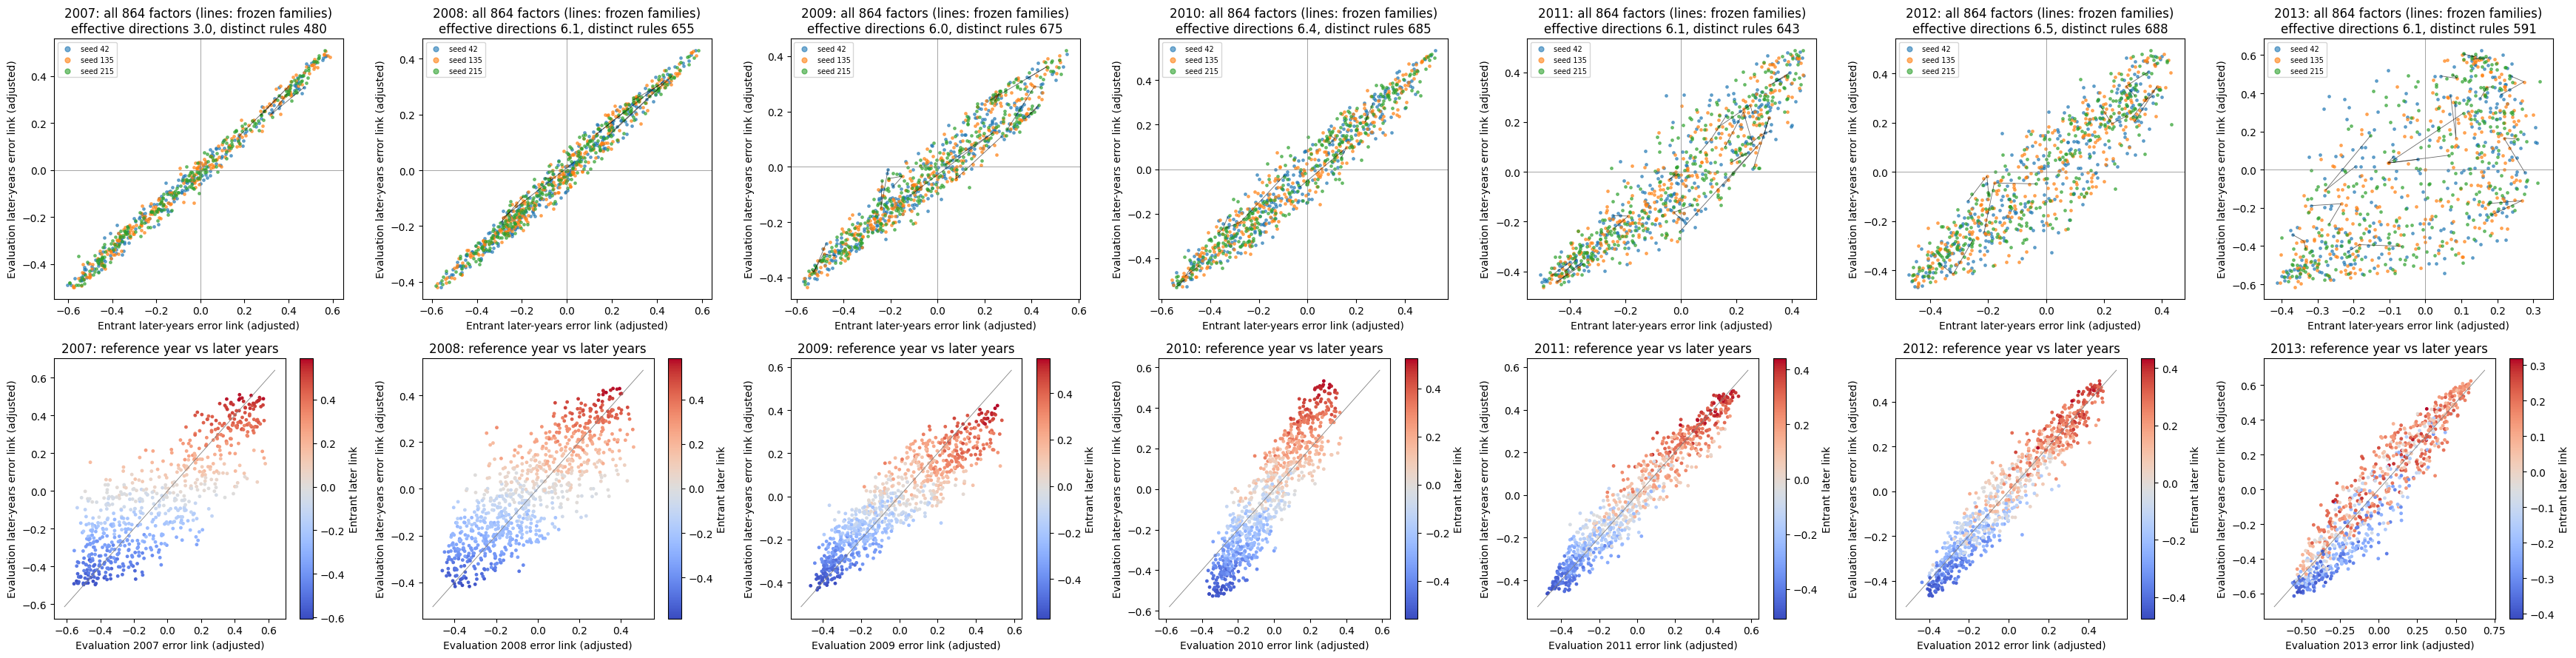

In [23]:
fig, axes = plt.subplots(2, len(cases), figsize=(5 * len(cases), 9), squeeze=False)
for col, case in enumerate(cases):
    ref, results = case['reference'], analysis[case['reference']]
    links = results['factor_links'].query("target == 'adjusted'")
    entrant = links.query("set == 'entrants' and period == 'later'").set_index('factor')
    later = links.query("set == 'evaluation' and period == 'later'").set_index('factor')
    ref_text = str(ref); first = links.query("set == 'evaluation' and period == @ref_text").set_index('factor')
    ax = axes[0, col]
    for seed in (42, 135, 215):
        names = [n for n in results['factor_names'] if n.startswith(f'{seed}:')]
        ax.scatter(entrant.loc[names, 'value'], later.loc[names, 'value'], s=6, alpha=.6, label=f'seed {seed}')
    for family in case['families']:
        members = [f'{s}:{k}' for s, k in family['members']]
        ax.plot(entrant.loc[members, 'value'], later.loc[members, 'value'], color='black', lw=.6, alpha=.6)
    ax.axhline(0, color='grey', lw=.5); ax.axvline(0, color='grey', lw=.5); ax.legend(fontsize=7, markerscale=2)
    ax.set(title=f"{ref}: all {len(entrant)} factors (lines: frozen families)\neffective directions {results['effective_dimension']:.1f}, distinct rules {len(results['factor_rules'])}",
           xlabel='Entrant later-years error link (adjusted)', ylabel='Evaluation later-years error link (adjusted)')
    ax = axes[1, col]
    points = ax.scatter(first['value'], later.loc[first.index, 'value'], c=entrant.loc[first.index, 'value'], cmap='coolwarm', s=6)
    limits = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]; ax.plot(limits, limits, color='grey', lw=.6)
    fig.colorbar(points, ax=ax, label='Entrant later link')
    ax.set(title=f'{ref}: reference year vs later years', xlabel=f'Evaluation {ref} error link (adjusted)', ylabel='Evaluation later-years error link (adjusted)')
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_07_factor_scan.png', dpi=160); plt.show()

Both axes of the top row use the same adjusted target; plain and score-alone links, every year, and the reference → later change with patient intervals are in `*_factor_links.csv`. Points far from the origin on both axes mark where the model errs in both patient sets; lines joining a frozen family's members show whether seeds agree — partly the same few directions seen several times. In the bottom row, points above the diagonal became more linked to errors after the reference year; their colour (entrant estimate) is the guard against reading regression to the mean as emergence.

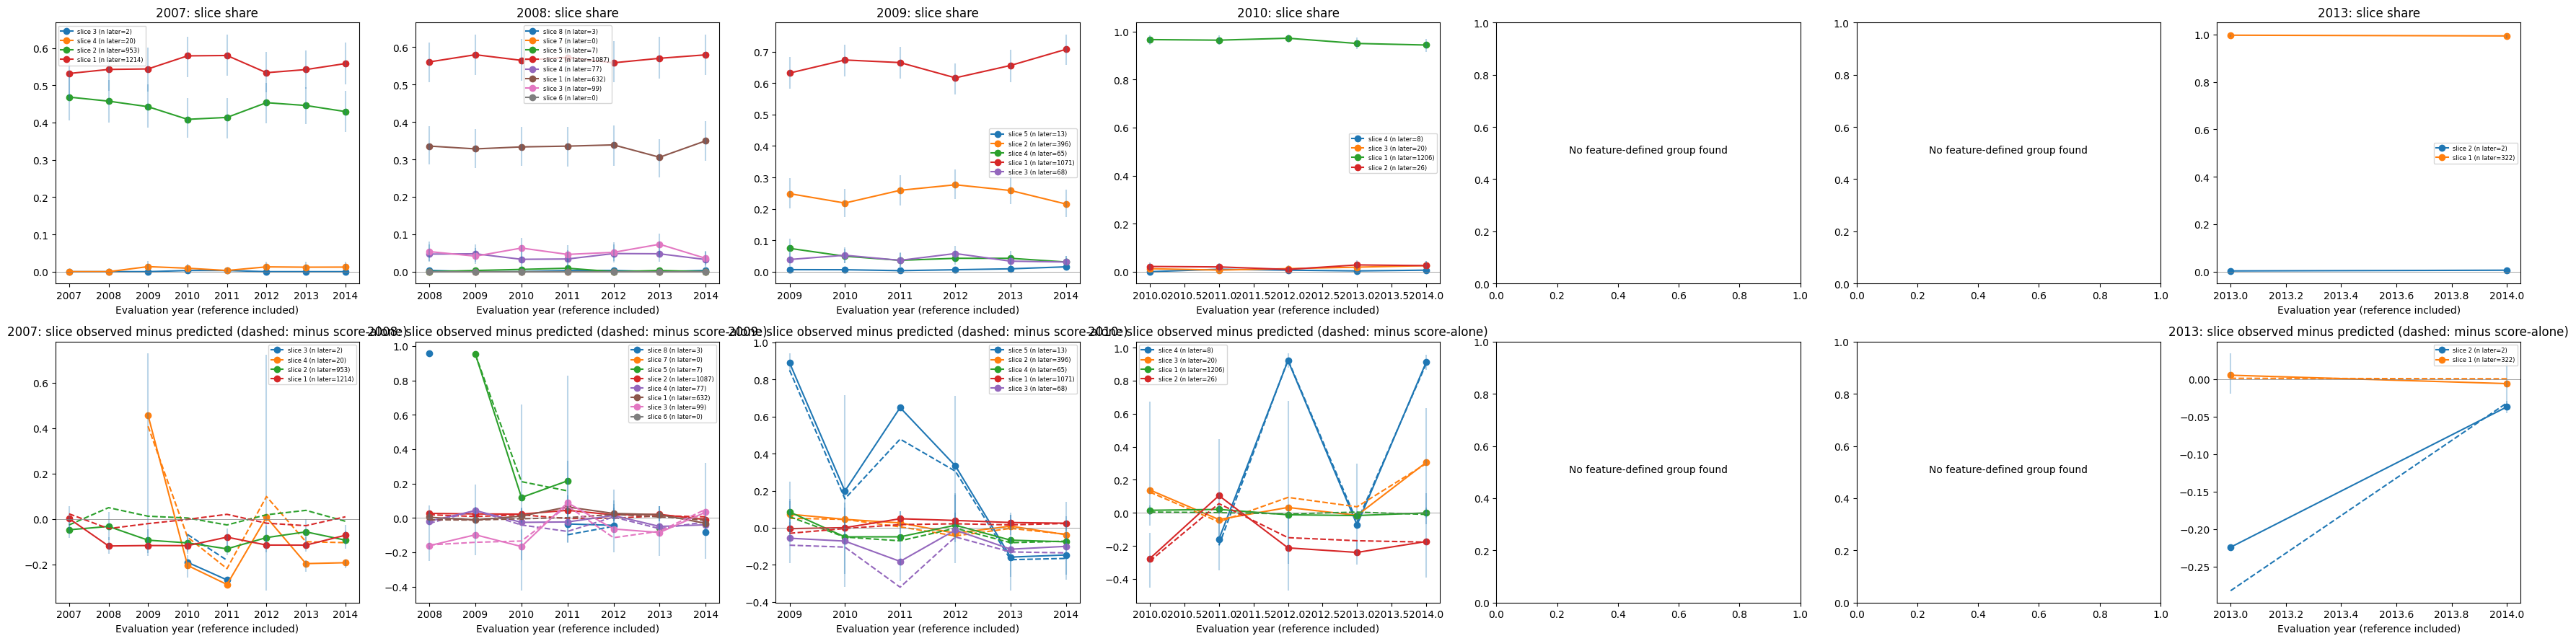

In [24]:
fig, axes = plt.subplots(2, len(cases), figsize=(5 * len(cases), 9), squeeze=False)
for col, case in enumerate(cases):
    ref, results = case['reference'], analysis[case['reference']]
    reports = results['slice_reports']
    for row, quantity in enumerate(('share', 'observed_minus_predicted')):
        ax = axes[row, col]
        if reports.empty:
            ax.text(.5, .5, results['slice_status'], ha='center', wrap=True, transform=ax.transAxes); continue
        for name in results['slices']['slice']:
            part = reports.query("slice == @name and cohort == 'all' and quantity == @quantity and period != 'later'")
            x = part['period'].astype(int); ax.plot(x, part['value'], marker='o', label=f"{name} (n later={int(part[part['period'] != str(ref)]['rows'].sum())})")
            ax.vlines(x, part['low'], part['high'], alpha=.3)
            if quantity == 'observed_minus_predicted':
                alone = reports.query("slice == @name and cohort == 'all' and quantity == 'observed_minus_score_alone' and period != 'later'")
                ax.plot(alone['period'].astype(int), alone['value'], ls='--', color=ax.lines[-1].get_color())
        ax.axhline(0, color='grey', lw=.5); ax.legend(fontsize=6)
        ax.set(title=f'{ref}: slice {quantity.replace("_", " ")}' + (' (dashed: minus score-alone)' if row else ''), xlabel='Evaluation year (reference included)')
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_08_slices.png', dpi=160); plt.show()

A slice whose share grows or whose observed minus predicted mortality moves away from zero after the reference year is a candidate description of the new errors. Read the plain gap beside observed minus score-alone risk (`*_slice_reports.csv`), and the newcomer/returning split: a slice carried by newcomers is a population change.

## 7. Are the error groups present in the context?

For each existing rule, each factor rule and each slice, over the predictor's whole context window: share among context deaths, among later deaths and among later missed deaths (and the same three for survivors and false alarms). Context shares have no interval; later shares have patient intervals except for factor rules (point values). Presence is not sufficient evidence (death rows are in every context); only absence is flagged, as either *no matching context rows* or *matching rows but no deaths*. Expectation stated up front: factor rules are broad groups of dense factors and contexts hold thousands of rows, so absence will probably not occur for them; slices can show it.

In [25]:
tick = time.perf_counter()
for case in cases:
    ref, results, evaluation, context = case['reference'], analysis[case['reference']], case['views']['evaluation'], case['context']
    if not np.isin(context['labels'], [0, 1]).all():
        raise ValueError(f'{ref}: context rows without a binary outcome')
    groups = [('existing', c['record']['concept'], c['rule']) for c in case['concepts']]
    groups += [('factor_rule', key, value['rule']) for key, value in results['factor_rules'].items()]
    groups += [('slice', key, rule) for key, rule in results['slice_rules'].items()]
    rows = [dict(reference=ref, kind=kind, group=key, **ep.context_shares(ep.rule_mask(rule, context['features']), context['labels'],
                                                                         ep.rule_mask(rule, evaluation['features']), evaluation['frame'],
                                                                         results['weights'][:1] if kind == 'factor_rule' else results['weights'],
                                                                         case['threshold'], ref))
            for kind, key, rule in groups]
    results['context'] = pd.DataFrame(rows); results['context'].to_csv(OUTPUT / f'{ref}_context_shares.csv', index=False)
    print(f"{ref}: context {len(context['labels'])} rows, years {int(context['years'].min())}–{int(context['years'].max())}")
    display(results['context'].groupby(['kind', 'absence']).size().rename('groups').reset_index())
timings['7 context'] = time.perf_counter() - tick

2007: context 946 rows, years 2007–2007


,kind,absence,groups
0,existing,context deaths present,2
1,existing,matching context rows but no deaths,2
2,factor_rule,context deaths present,340
3,factor_rule,matching context rows but no deaths,102
4,factor_rule,no matching context rows,38
5,slice,context deaths present,3
6,slice,matching context rows but no deaths,1


2008: context 3091 rows, years 2007–2008


,kind,absence,groups
0,existing,context deaths present,6
1,factor_rule,context deaths present,580
2,factor_rule,matching context rows but no deaths,53
3,factor_rule,no matching context rows,22
4,slice,context deaths present,7
5,slice,no matching context rows,1


2009: context 5520 rows, years 2007–2009


,kind,absence,groups
0,existing,context deaths present,9
1,existing,matching context rows but no deaths,1
2,factor_rule,context deaths present,627
3,factor_rule,matching context rows but no deaths,36
4,factor_rule,no matching context rows,12
5,slice,context deaths present,5


... (4 outputs left out)

2012: context 6329 rows, years 2010–2012


,kind,absence,groups
0,existing,context deaths present,7
1,factor_rule,context deaths present,594
2,factor_rule,matching context rows but no deaths,61
3,factor_rule,no matching context rows,33


2013: context 6276 rows, years 2011–2013


,kind,absence,groups
0,existing,context deaths present,13
1,existing,matching context rows but no deaths,1
2,factor_rule,context deaths present,529
3,factor_rule,matching context rows but no deaths,33
4,factor_rule,no matching context rows,29
5,slice,context deaths present,2


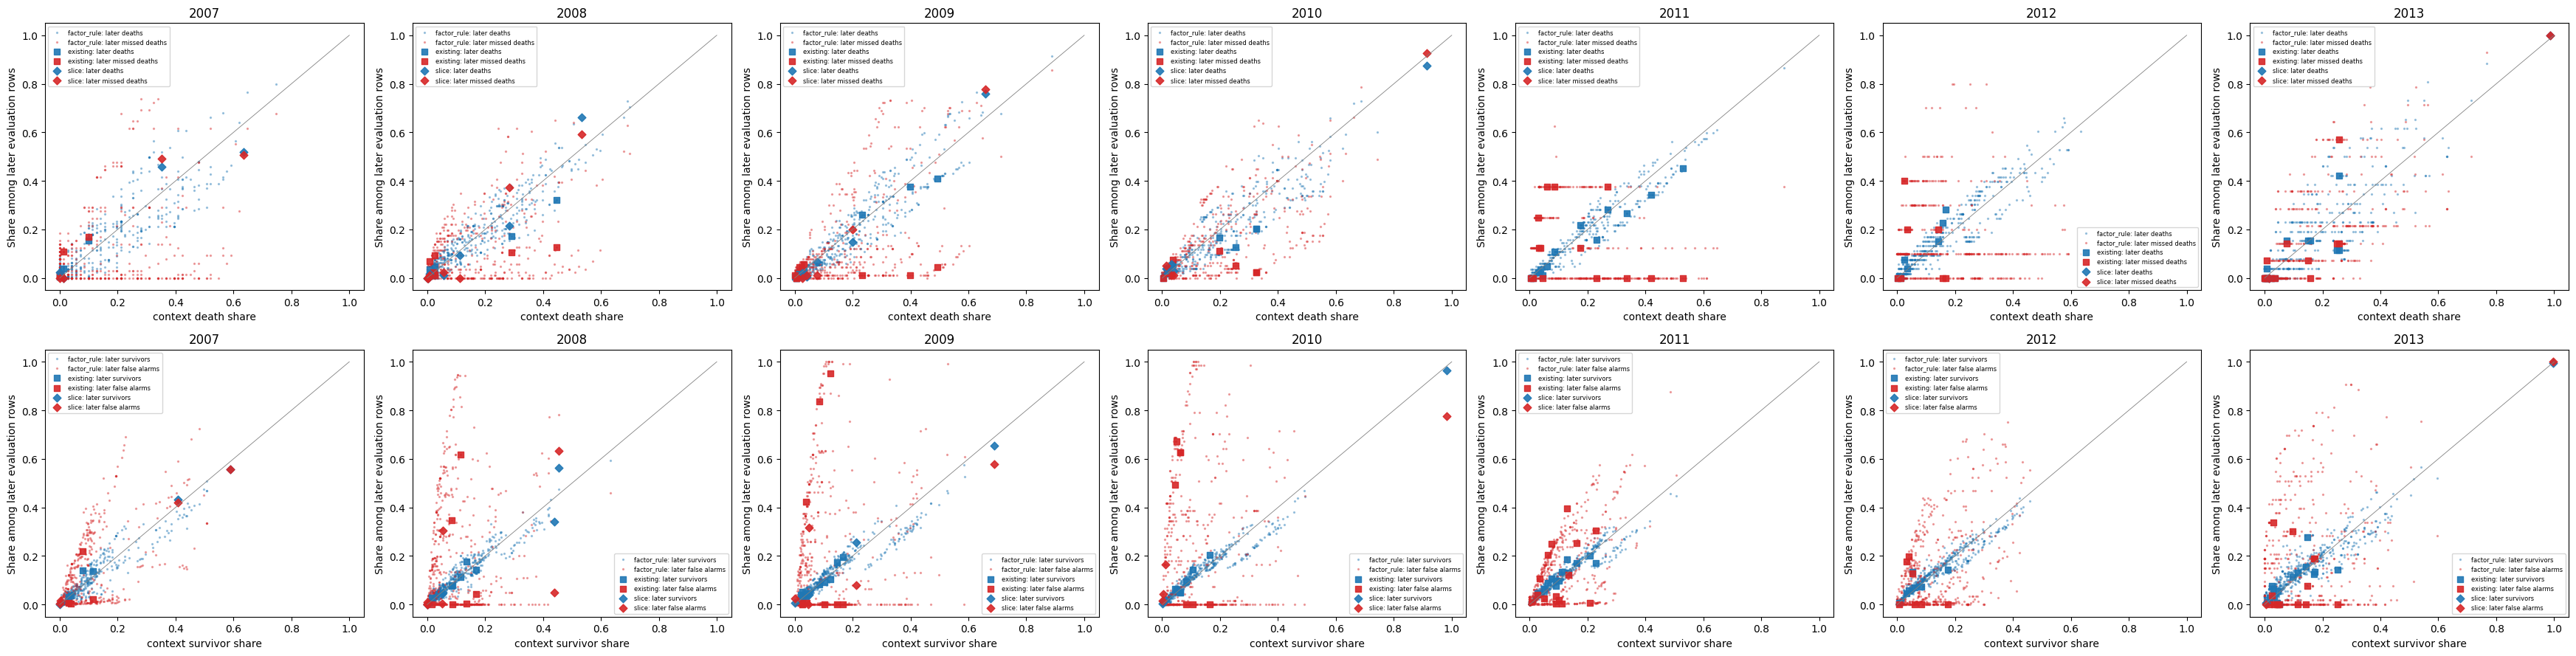

In [26]:
fig, axes = plt.subplots(2, len(cases), figsize=(5 * len(cases), 9), squeeze=False)
for col, case in enumerate(cases):
    table = analysis[case['reference']]['context']
    for row, (context_col, later_cols) in enumerate((('context_death_share', ('later_deaths', 'later_missed_deaths')),
                                                     ('context_survivor_share', ('later_survivors', 'later_false_alarms')))):
        ax = axes[row, col]
        for kind, marker in (('factor_rule', '.'), ('existing', 's'), ('slice', 'D')):
            part = table[table['kind'] == kind]
            for name, colour in zip(later_cols, ('tab:blue', 'tab:red')):
                ax.scatter(part[context_col], part[f'{name}_share'], marker=marker, s=8 if kind == 'factor_rule' else 30,
                           color=colour, alpha=.35 if kind == 'factor_rule' else .9, label=f'{kind}: {name.replace("_", " ")}')
        ax.plot([0, 1], [0, 1], color='grey', lw=.6); ax.legend(fontsize=6)
        ax.set(title=f"{case['reference']}", xlabel=context_col.replace('_', ' '), ylabel='Share among later evaluation rows')
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_09_context_shares.png', dpi=160); plt.show()

Points well above the diagonal are groups more common among later deaths (or missed deaths) than among the context's deaths: under-represented in what the predictor sees. Absence cases, if any, are counted in the table above and listed in the context file.

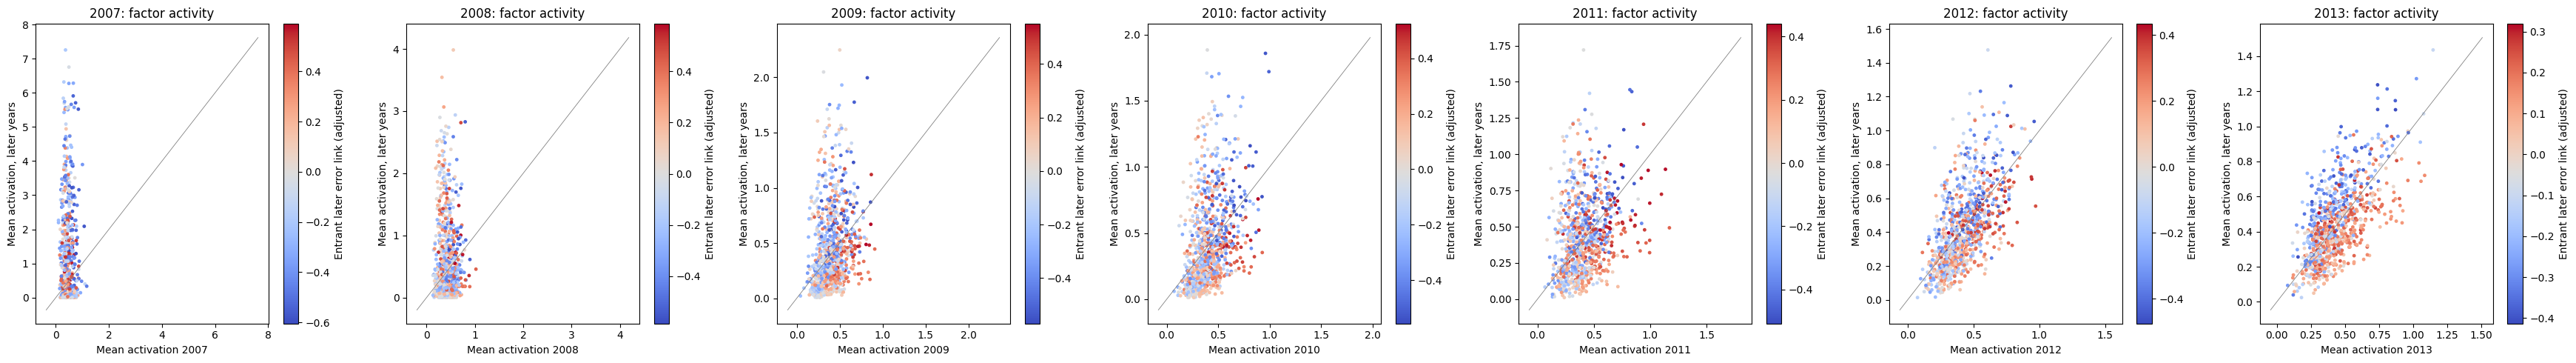

In [27]:
fig, axes = plt.subplots(1, len(cases), figsize=(5 * len(cases), 5), squeeze=False)
for col, case in enumerate(cases):
    ref, results = case['reference'], analysis[case['reference']]
    activity = results['factor_activity'].query("group == 'all' and quantity.str.endswith('|mean_activation')", engine='python')
    first = activity[activity['period'] == str(ref)].assign(factor=lambda t: t['quantity'].str.split('|').str[0]).set_index('factor')
    later = activity.query("period == 'later'").assign(factor=lambda t: t['quantity'].str.split('|').str[0]).set_index('factor')
    colour = results['factor_links'].query("set == 'entrants' and period == 'later' and target == 'adjusted'").set_index('factor')['value']
    ax = axes[0, col]
    points = ax.scatter(first['value'], later.loc[first.index, 'value'], c=colour.loc[first.index], cmap='coolwarm', s=6)
    limits = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]; ax.plot(limits, limits, color='grey', lw=.6)
    fig.colorbar(points, ax=ax, label='Entrant later error link (adjusted)')
    ax.set(title=f'{ref}: factor activity', xlabel=f'Mean activation {ref}', ylabel='Mean activation, later years')
fig.tight_layout(); fig.savefig(OUTPUT / 'figure_12_factor_activity.png', dpi=160); plt.show()

Factors above the diagonal became stronger after the reference year. Caveat: the year input and the score shift move many factors together, so a factor getting stronger is not by itself a finding about that factor; the colour shows whether the stronger ones are also those the entrants link to errors.

## 8. Evidence table

One long table per predictor gathering, for every existing concept, factor rule and slice: rule share by year, inside error rates (observed and score-alone), sensitivity, mean months with care, and context shares, with counts, and patient intervals where given (factor rules: point values). No verdict column. With hundreds of factor rules this is several hundred thousand numbers — nobody reads them all, so the reader ends up choosing what to look at. The fixed ordering is the guard: existing concepts in frozen key order, factor rules and slices by their entrant estimate (highest adjusted error link / residual first). Full tables are written to files.

In [28]:
tick = time.perf_counter()
for case in cases:
    ref, results, evaluation = case['reference'], analysis[case['reference']], case['views']['evaluation']
    frame, months = evaluation['frame'], evaluation['frame']['active_months'].to_numpy(float)
    entrant_link = results['factor_links'].query("set == 'entrants' and period == 'later' and target == 'adjusted'").set_index('factor')['value']
    order = [('existing', c['record']['concept'], c['rule'], i) for i, c in enumerate(case['concepts'])]
    order += sorted([('factor_rule', key, v['rule'], -np.nan_to_num(entrant_link.loc[v['factors']].max(), nan=-np.inf)) for key, v in results['factor_rules'].items()], key=lambda g: (g[3], g[1]))
    order += [('slice', name, results['slice_rules'][name], i) for i, name in enumerate(results['slices']['slice'])]
    parts = []
    entrant_estimate = {key: entrant_link.loc[v['factors']].max() for key, v in results['factor_rules'].items()}
    entrant_estimate |= dict(zip(results['slices']['slice'], results['slices']['entrant_mean_target']))
    factors = {key: ' '.join(v['factors']) for key, v in results['factor_rules'].items()}
    for position, (kind, key, rule, _) in enumerate(order):
        group_parts = []
        member = ep.rule_mask(rule, evaluation['features'])
        weights = results['weights'][:1] if kind == 'factor_rule' else results['weights']
        rates = ep.rule_error_rates(frame, member, weights, case['threshold'], ref, results['risks'][:len(weights)]).query("group == 'inside'")
        group_parts.append(rates.assign(measure=lambda t: 'inside_' + t['side'] + '_error_rate_' + t['version']))
        profile = ep.year_profile(frame, {'rule_share': member.astype(float), 'months_with_care_in_rule': np.where(member, months, np.nan)},
                                  weights, case['threshold'], ref)[0].query("group == 'all'")
        group_parts.append(profile.rename(columns={'quantity': 'measure'}))
        context = results['context'].query('group == @key and kind == @kind').iloc[0]
        group_parts.append(pd.DataFrame([dict(period='context/later', measure=name, value=context[name]) for name in context.index
                                   if name.endswith('_share') or name in ('absence', 'matching_rows', 'matching_deaths')]))
        if kind == 'existing':
            group_parts.append(results['concept_splits'].query('concept == @key').assign(measure=lambda t: 'size_within_split_' + t['component'] + '_' + t['side'] + '_' + t['version'],
                                                                                   period=lambda t: t['start'] + '→' + t['end']))
        else:
            quantity = f"{key}|log_odds_sensitivity"
            profiles = results['factor_rule_profiles'] if kind == 'factor_rule' else results['slice_profiles']
            group_parts.append(profiles[(profiles['quantity'] == quantity) & (profiles['group'] == 'all')].assign(measure='log_odds_sensitivity') if len(profiles) else pd.DataFrame())
        if kind == 'existing':
            group_parts.append(results['concept_profiles'].query("concept == @key and quantity == 'log_odds_sensitivity' and group == 'all'").assign(measure='log_odds_sensitivity'))
        parts += [p.assign(order=position, kind=kind, group=key, factors=factors.get(key, ''), entrant_estimate=entrant_estimate.get(key, np.nan),
                               rule_text=ep.rule_text(rule, case['feature_names']) if kind != 'existing' else key)
                      for p in group_parts]
    sensitivity = pd.concat([results['concept_profiles'].query("quantity == 'log_odds_sensitivity' and group == 'all'").assign(quantity=lambda t: t['concept'] + '|log_odds_sensitivity'),
                             results['factor_rule_profiles'], results['slice_profiles']], ignore_index=True)
    sensitivity = sensitivity[sensitivity['quantity'].str.endswith('log_odds_sensitivity') & (sensitivity['group'] == 'all')]
    evidence = pd.concat(parts, ignore_index=True)
    columns = ['order', 'kind', 'group', 'factors', 'entrant_estimate', 'rule_text', 'measure', 'period', 'side', 'version', 'rows', 'patients', 'deaths', 'numerator', 'denominator',
               'value', 'low', 'high', 'valid_draws', 'undefined_draws', 'degenerate_interval', 'estimate_status']
    evidence = evidence[[c for c in columns if c in evidence]]
    evidence.to_csv(OUTPUT / f'{ref}_evidence_table.csv.gz', index=False)
    sensitivity.to_csv(OUTPUT / f'{ref}_evidence_sensitivity.csv', index=False)
    results['new_rule_directions'].to_csv(OUTPUT / f'{ref}_evidence_direction_fits.csv', index=False)
    ref_text = str(ref)
    print(f'{ref}: evidence table {len(evidence)} rows for {len(order)} groups')
    display(evidence.query("kind != 'factor_rule' and measure in ['inside_deaths_error_rate_observed', 'rule_share'] and period in [@ref_text, 'later']"))
timings['8 evidence'] = time.perf_counter() - tick

2007: evidence table 35808 rows for 488 groups


,order,kind,group,factors,entrant_estimate,rule_text,measure,period,side,version,...,deaths,numerator,denominator,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status
0,0,existing,"r1/2007/2007/42/42:1,135:175,215:120",,NaN,"r1/2007/2007/42/42:1,135:175,215:120",inside_deaths_error_rate_observed,2007,deaths,observed,...,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1000.0,False,not estimable
32,0,existing,"r1/2007/2007/42/42:1,135:175,215:120",,NaN,"r1/2007/2007/42/42:1,135:175,215:120",inside_deaths_error_rate_observed,later,deaths,observed,...,1.0,1.0,1.0,1.0,1.000000,1.000000,615.0,385.0,True,estimated
36,0,existing,"r1/2007/2007/42/42:1,135:175,215:120",,NaN,"r1/2007/2007/42/42:1,135:175,215:120",rule_share,2007,NaN,NaN,...,18.0,9.0,237.0,0.037975,0.016598,0.063843,1000.0,0.0,False,estimated
52,0,existing,"r1/2007/2007/42/42:1,135:175,215:120",,NaN,"r1/2007/2007/42/42:1,135:175,215:120",rule_share,later,NaN,NaN,...,175.0,78.0,2189.0,0.035633,0.025011,0.047003,1000.0,0.0,False,estimated
240,1,existing,"r1/2007/2007/42/42:268,135:171,215:262",,NaN,"r1/2007/2007/42/42:268,135:171,215:262",inside_deaths_error_rate_observed,2007,deaths,observed,...,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1000.0,False,not estimable
272,1,existing,"r1/2007/2007/42/42:268,135:171,215:262",,NaN,"r1/2007/2007/42/42:268,135:171,215:262",inside_deaths_error_rate_observed,later,deaths,observed,...,1.0,1.0,1.0,1.0,1.000000,1.000000,632.0,368.0,True,estimated
276,1,existing,"r1/2007/2007/42/42:268,135:171,215:262",,NaN,"r1/2007/2007/42/42:268,135:171,215:262",rule_share,2007,NaN,NaN,...,18.0,7.0,237.0,0.029536,0.009007,0.052425,1000.0,0.0,False,estimated
292,1,existing,"r1/2007/2007/42/42:268,135:171,215:262",,NaN,"r1/2007/2007/42/42:268,135:171,215:262",rule_share,later,NaN,NaN,...,175.0,63.0,2189.0,0.02878,0.018479,0.039536,1000.0,0.0,False,estimated
480,2,existing,"r1/2007/2007/42/42:65,135:187,215:78",,NaN,"r1/2007/2007/42/42:65,135:187,215:78",inside_deaths_error_rate_observed,2007,deaths,observed,...,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1000.0,False,not estimable
512,2,existing,"r1/2007/2007/42/42:65,135:187,215:78",,NaN,"r1/2007/2007/42/42:65,135:187,215:78",inside_deaths_error_rate_observed,later,deaths,observed,...,7.0,7.0,7.0,1.0,1.000000,1.000000,999.0,1.0,True,estimated


2008: evidence table 44349 rows for 669 groups


,order,kind,group,factors,entrant_estimate,rule_text,measure,period,side,version,...,deaths,numerator,denominator,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status
0,0,existing,"all_history/2008/2008/42/42:0,135:24,215:233",,NaN,"all_history/2008/2008/42/42:0,135:24,215:233",inside_deaths_error_rate_observed,2008,deaths,observed,...,5.0,4.0,5.0,0.8,0.333333,1.000000,994.0,6.0,False,estimated
28,0,existing,"all_history/2008/2008/42/42:0,135:24,215:233",,NaN,"all_history/2008/2008/42/42:0,135:24,215:233",inside_deaths_error_rate_observed,later,deaths,observed,...,28.0,9.0,28.0,0.321429,0.160000,0.500000,1000.0,0.0,False,estimated
32,0,existing,"all_history/2008/2008/42/42:0,135:24,215:233",,NaN,"all_history/2008/2008/42/42:0,135:24,215:233",rule_share,2008,NaN,NaN,...,22.0,30.0,298.0,0.100671,0.067335,0.134682,1000.0,0.0,False,estimated
46,0,existing,"all_history/2008/2008/42/42:0,135:24,215:233",,NaN,"all_history/2008/2008/42/42:0,135:24,215:233",rule_share,later,NaN,NaN,...,162.0,162.0,1905.0,0.085039,0.072387,0.099408,1000.0,0.0,False,estimated
209,1,existing,"all_history/2008/2008/42/42:142,135:265,215:184",,NaN,"all_history/2008/2008/42/42:142,135:265,215:184",inside_deaths_error_rate_observed,2008,deaths,observed,...,1.0,1.0,1.0,1.0,1.000000,1.000000,646.0,354.0,True,estimated
237,1,existing,"all_history/2008/2008/42/42:142,135:265,215:184",,NaN,"all_history/2008/2008/42/42:142,135:265,215:184",inside_deaths_error_rate_observed,later,deaths,observed,...,6.0,6.0,6.0,1.0,1.000000,1.000000,993.0,7.0,True,estimated
241,1,existing,"all_history/2008/2008/42/42:142,135:265,215:184",,NaN,"all_history/2008/2008/42/42:142,135:265,215:184",rule_share,2008,NaN,NaN,...,22.0,8.0,298.0,0.026846,0.009899,0.049478,1000.0,0.0,False,estimated
255,1,existing,"all_history/2008/2008/42/42:142,135:265,215:184",,NaN,"all_history/2008/2008/42/42:142,135:265,215:184",rule_share,later,NaN,NaN,...,162.0,53.0,1905.0,0.027822,0.020227,0.036632,1000.0,0.0,False,estimated
418,2,existing,"all_history/2008/2008/42/42:218,135:228,215:236",,NaN,"all_history/2008/2008/42/42:218,135:228,215:236",inside_deaths_error_rate_observed,2008,deaths,observed,...,9.0,4.0,9.0,0.444444,0.111111,0.800000,998.0,2.0,False,estimated
446,2,existing,"all_history/2008/2008/42/42:218,135:228,215:236",,NaN,"all_history/2008/2008/42/42:218,135:228,215:236",inside_deaths_error_rate_observed,later,deaths,observed,...,52.0,11.0,52.0,0.211538,0.108657,0.321444,1000.0,0.0,False,estimated


2009: evidence table 41220 rows for 690 groups


,order,kind,group,factors,entrant_estimate,rule_text,measure,period,side,version,...,deaths,numerator,denominator,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status
0,0,existing,"all_history/2009/2009/42/42:134,135:207,215:5",,NaN,"all_history/2009/2009/42/42:134,135:207,215:5",inside_deaths_error_rate_observed,2009,deaths,observed,...,2.0,2.0,2.0,1.0,1.000000,1.000000,879.0,121.0,True,estimated
24,0,existing,"all_history/2009/2009/42/42:134,135:207,215:5",,NaN,"all_history/2009/2009/42/42:134,135:207,215:5",inside_deaths_error_rate_observed,later,deaths,observed,...,5.0,5.0,5.0,1.0,1.000000,1.000000,992.0,8.0,True,estimated
28,0,existing,"all_history/2009/2009/42/42:134,135:207,215:5",,NaN,"all_history/2009/2009/42/42:134,135:207,215:5",rule_share,2009,NaN,NaN,...,27.0,47.0,310.0,0.151613,0.113148,0.194309,1000.0,0.0,False,estimated
40,0,existing,"all_history/2009/2009/42/42:134,135:207,215:5",,NaN,"all_history/2009/2009/42/42:134,135:207,215:5",rule_share,later,NaN,NaN,...,149.0,259.0,1613.0,0.16057,0.132871,0.189040,1000.0,0.0,False,estimated
178,1,existing,"all_history/2009/2009/42/42:157,135:223,215:199",,NaN,"all_history/2009/2009/42/42:157,135:223,215:199",inside_deaths_error_rate_observed,2009,deaths,observed,...,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1000.0,False,not estimable
202,1,existing,"all_history/2009/2009/42/42:157,135:223,215:199",,NaN,"all_history/2009/2009/42/42:157,135:223,215:199",inside_deaths_error_rate_observed,later,deaths,observed,...,1.0,1.0,1.0,1.0,1.000000,1.000000,646.0,354.0,True,estimated
206,1,existing,"all_history/2009/2009/42/42:157,135:223,215:199",,NaN,"all_history/2009/2009/42/42:157,135:223,215:199",rule_share,2009,NaN,NaN,...,27.0,6.0,310.0,0.019355,0.006250,0.036679,1000.0,0.0,False,estimated
218,1,existing,"all_history/2009/2009/42/42:157,135:223,215:199",,NaN,"all_history/2009/2009/42/42:157,135:223,215:199",rule_share,later,NaN,NaN,...,149.0,61.0,1613.0,0.037818,0.024712,0.052010,1000.0,0.0,False,estimated
356,2,existing,"all_history/2009/2009/42/42:172,135:72,215:41",,NaN,"all_history/2009/2009/42/42:172,135:72,215:41",inside_deaths_error_rate_observed,2009,deaths,observed,...,9.0,1.0,9.0,0.111111,0.000000,0.334091,1000.0,0.0,False,estimated
380,2,existing,"all_history/2009/2009/42/42:172,135:72,215:41",,NaN,"all_history/2009/2009/42/42:172,135:72,215:41",inside_deaths_error_rate_observed,later,deaths,observed,...,61.0,4.0,61.0,0.065574,0.014701,0.133333,1000.0,0.0,False,estimated


... (4 outputs left out)

2012: evidence table 26051 rows for 695 groups


,order,kind,group,factors,entrant_estimate,rule_text,measure,period,side,version,...,deaths,numerator,denominator,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status
0,0,existing,"last_3/2012/2012/42/42:118,135:25,215:248",,NaN,"last_3/2012/2012/42/42:118,135:25,215:248",inside_deaths_error_rate_observed,2012,deaths,observed,...,7.0,0.0,7.0,0.0,0.000000,0.000000,997.0,3.0,True,estimated
12,0,existing,"last_3/2012/2012/42/42:118,135:25,215:248",,NaN,"last_3/2012/2012/42/42:118,135:25,215:248",inside_deaths_error_rate_observed,later,deaths,observed,...,12.0,0.0,12.0,0.0,0.000000,0.000000,1000.0,0.0,True,estimated
16,0,existing,"last_3/2012/2012/42/42:118,135:25,215:248",,NaN,"last_3/2012/2012/42/42:118,135:25,215:248",rule_share,2012,NaN,NaN,...,27.0,16.0,316.0,0.050633,0.026576,0.076643,1000.0,0.0,False,estimated
22,0,existing,"last_3/2012/2012/42/42:118,135:25,215:248",,NaN,"last_3/2012/2012/42/42:118,135:25,215:248",rule_share,later,NaN,NaN,...,53.0,38.0,627.0,0.060606,0.041792,0.078866,1000.0,0.0,False,estimated
85,1,existing,"last_3/2012/2012/42/42:12,135:219,215:273",,NaN,"last_3/2012/2012/42/42:12,135:219,215:273",inside_deaths_error_rate_observed,2012,deaths,observed,...,7.0,0.0,7.0,0.0,0.000000,0.000000,1000.0,0.0,True,estimated
97,1,existing,"last_3/2012/2012/42/42:12,135:219,215:273",,NaN,"last_3/2012/2012/42/42:12,135:219,215:273",inside_deaths_error_rate_observed,later,deaths,observed,...,15.0,0.0,15.0,0.0,0.000000,0.000000,1000.0,0.0,True,estimated
101,1,existing,"last_3/2012/2012/42/42:12,135:219,215:273",,NaN,"last_3/2012/2012/42/42:12,135:219,215:273",rule_share,2012,NaN,NaN,...,27.0,16.0,316.0,0.050633,0.029115,0.076413,1000.0,0.0,False,estimated
107,1,existing,"last_3/2012/2012/42/42:12,135:219,215:273",,NaN,"last_3/2012/2012/42/42:12,135:219,215:273",rule_share,later,NaN,NaN,...,53.0,49.0,627.0,0.07815,0.056336,0.101494,1000.0,0.0,False,estimated
170,2,existing,"last_3/2012/2012/42/42:151,135:238,215:234",,NaN,"last_3/2012/2012/42/42:151,135:238,215:234",inside_deaths_error_rate_observed,2012,deaths,observed,...,6.0,2.0,6.0,0.333333,0.000000,0.750000,998.0,2.0,False,estimated
182,2,existing,"last_3/2012/2012/42/42:151,135:238,215:234",,NaN,"last_3/2012/2012/42/42:151,135:238,215:234",inside_deaths_error_rate_observed,later,deaths,observed,...,8.0,2.0,8.0,0.25,0.000000,0.600000,1000.0,0.0,False,estimated


2013: evidence table 18546 rows for 607 groups


,order,kind,group,factors,entrant_estimate,rule_text,measure,period,side,version,...,deaths,numerator,denominator,value,low,high,valid_draws,undefined_draws,degenerate_interval,estimate_status
0,0,existing,"last_3/2013/2013/42/42:119,135:148,215:255",,NaN,"last_3/2013/2013/42/42:119,135:148,215:255",inside_deaths_error_rate_observed,2013,deaths,observed,...,5.0,3.0,5.0,0.6,0.000000,1.000000,995.0,5.0,False,estimated
8,0,existing,"last_3/2013/2013/42/42:119,135:148,215:255",,NaN,"last_3/2013/2013/42/42:119,135:148,215:255",inside_deaths_error_rate_observed,later,deaths,observed,...,11.0,8.0,11.0,0.727273,0.444444,1.000000,1000.0,0.0,False,estimated
12,0,existing,"last_3/2013/2013/42/42:119,135:148,215:255",,NaN,"last_3/2013/2013/42/42:119,135:148,215:255",rule_share,2013,NaN,NaN,...,24.0,57.0,322.0,0.177019,0.138786,0.218654,1000.0,0.0,False,estimated
16,0,existing,"last_3/2013/2013/42/42:119,135:148,215:255",,NaN,"last_3/2013/2013/42/42:119,135:148,215:255",rule_share,later,NaN,NaN,...,26.0,94.0,324.0,0.290123,0.238561,0.340635,1000.0,0.0,False,estimated
54,1,existing,"last_3/2013/2013/42/42:132,135:261,215:217",,NaN,"last_3/2013/2013/42/42:132,135:261,215:217",inside_deaths_error_rate_observed,2013,deaths,observed,...,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1000.0,False,not estimable
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18502,605,slice,slice 2,,0.787366,DIAGN_I219 > 0.5,rule_share,later,NaN,NaN,...,26.0,2.0,324.0,0.006173,0.000000,0.016181,1000.0,0.0,False,estimated
18516,606,slice,slice 1,,-0.006454,DIAGN_I219 <= 0.5,inside_deaths_error_rate_observed,2013,deaths,observed,...,24.0,12.0,24.0,0.5,0.291667,0.714484,1000.0,0.0,False,estimated
18524,606,slice,slice 1,,-0.006454,DIAGN_I219 <= 0.5,inside_deaths_error_rate_observed,later,deaths,observed,...,26.0,14.0,26.0,0.538462,0.317986,0.733421,1000.0,0.0,False,estimated
18528,606,slice,slice 1,,-0.006454,DIAGN_I219 <= 0.5,rule_share,2013,NaN,NaN,...,24.0,321.0,322.0,0.996894,0.989966,1.000000,1000.0,0.0,False,estimated


In [29]:
import json
manifest.update(status='completed', elapsed_seconds=time.perf_counter() - started, section_seconds=timings, bootstrap_draws=BOOTSTRAP_DRAWS,
                direction_fits_per_new_rule=DIRECTION_FITS, tree_folds=TREE_FOLDS, workers=WORKERS, seed=SEED, tolerances=TOLERANCES,
                source_hashes=study['source_hashes'], input_hashes=study['input_hashes'], load_seconds=study['load_seconds'],
                predictors={case['reference']: dict(factor_rules=len(analysis[case['reference']]['factor_rules']),
                                                    slices=len(analysis[case['reference']]['slice_rules']),
                                                    effective_dimension=analysis[case['reference']]['effective_dimension'])
                            for case in cases})
(OUTPUT / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, default=str))
print(json.dumps({k: manifest[k] for k in ('elapsed_seconds', 'section_seconds', 'predictors')}, indent=2, default=str))

{
  "elapsed_seconds": 5602.427652268991,
  "section_seconds": {
    "0 load and parity": 17.03287316398928,
    "6a error links and activity": 3584.4168616809766,
    "6a factor descriptions": 1181.2660836899886,
    "6b slices": 8.921337000007043,
    "6c directions and sensitivity": 92.08298542600824,
    "7 context": 2.073682609014213,
    "8 evidence": 260.1390891530027
  },
  "predictors": {
    "2007": {
      "factor_rules": 480,
      "slices": 4,
      "effective_dimension": 2.9660567019111506
    },
    "2008": {
      "factor_rules": 655,
      "slices": 8,
      "effective_dimension": 6.135353702181421
    },
    "2009": {
      "factor_rules": 675,
      "slices": 5,
      "effective_dimension": 5.956609366358845
    },
    "2010": {
      "factor_rules": 685,
      "slices": 4,
      "effective_dimension": 6.430985823826583
    },
    "2011": {
      "factor_rules": 643,
      "slices": 0,
      "effective_dimension": 6.054343690505784
    },
    "2012": {
      "factor_